## Preparation


### Load dependencies


In [ ]:
from io import BytesIO
from typing import Any, Dict, List, Literal, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import mordred as md
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch, PathPatch, Rectangle
from numpy.typing import NDArray
from tqdm.auto import tqdm
from tqdm.contrib.concurrent import thread_map

from nist_polar_filtering import BASE_DIR, SEED, MODEL_NAMES, HATCH_DICT
from nist_polar_filtering.utils import load_predicted_df
from sklearn.metrics import auc
import json
from yellow_cards_workflow.calculations import calc_groups, calc_classification_metrics
from yellow_cards_workflow.data_analysis import plot_stats_classification
from yellow_cards_workflow.calculations import (
    calc_basic_stats,
    calc_models_diffs,
    calc_diffs_corrs,
)
from yellow_cards_workflow.data_analysis import (
    plot_delta_correlations,
    plot_group_sizes,
    plot_stats_group,
)

### Functions


### Set Palette


In [4]:
colorblind = sns.color_palette("colorblind")
colorblind

[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [5]:
new_order = [colorblind[i] for i in [0, 3, 7, 2, 5, 4, 6, 8, 1, 9]]
sns.color_palette(new_order)

[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [6]:
sns.set_context("paper", font_scale=0.7)
plt.rcParams["figure.dpi"] = 1000

### Load Datasets


In [ ]:
phases_dict = json.load((BASE_DIR / "data/output/phases-23-all.json").open("r"))
polar_df = pd.read_parquet(BASE_DIR / "data/processed/25_models.parquet")

In [ ]:
MODEL_NAMES = [
    x for x in polar_df.columns if x.startswith(("gnn", "fcfp", "fcd", "cnn", "cb"))
]
GNN_MODELS = [x for x in polar_df.columns if (x.startswith("gnn-"))]

In [22]:
MODEL_NAMES

['cnn-42',
 'cnn-43',
 'cnn-44',
 'cnn-45',
 'cnn-46',
 'fcd-42',
 'fcd-43',
 'fcd-44',
 'fcd-45',
 'fcd-46',
 'fcfp-42',
 'fcfp-43',
 'fcfp-44',
 'fcfp-45',
 'fcfp-46',
 'cb-42',
 'cb-43',
 'cb-44',
 'cb-45',
 'cb-46',
 'gnn-42',
 'gnn-43',
 'gnn-44',
 'gnn-45',
 'gnn-46']

In [23]:
GNN_MODELS

['gnn-42',
 'gnn-43',
 'gnn-44',
 'gnn-45',
 'gnn-46',
 'gnn-47',
 'gnn-48',
 'gnn-49',
 'gnn-50',
 'gnn-51',
 'gnn-52',
 'gnn-53']

## Stats Calculation


In [47]:
len(polar_df)

89469

In [ ]:
temp = polar_df.groupby(["inchikey"]).mean(numeric_only=True)
(temp[MODEL_NAMES].median(axis=1) - temp["ri"]).abs().describe()

count    1.106100e+04
mean     6.093483e-02
std      1.177136e-01
min      2.288818e-08
25%      6.867485e-03
50%      2.121995e-02
75%      6.113998e-02
max      2.660190e+00
dtype: float64

In [ ]:
temp = polar_df.groupby(["inchikey"]).mean(numeric_only=True)
(temp[GNN_MODELS].median(axis=1) - temp["ri"]).abs().describe()

count    11061.000000
mean         0.063009
std          0.124917
min          0.000005
25%          0.007120
50%          0.021303
75%          0.064330
max          3.558010
dtype: float64

In [ ]:
temp = polar_df.groupby(["inchikey"]).mean(numeric_only=True)
(temp[MODEL_NAMES].median(axis=1) - temp["ri"]).abs().describe(
    percentiles=[0.5, 0.75, 0.95]
)

count    1.106100e+04
mean     6.093483e-02
std      1.177136e-01
min      2.288818e-08
50%      2.121995e-02
75%      6.113998e-02
95%      2.541600e-01
max      2.660190e+00
dtype: float64

### MAE


Fraction of silylated entries

In [ ]:
res = polar_df.loc[[True if "Si" not in x else False for x in polar_df["inchi"]], :]
res.join(calc_basic_stats(res, MODEL_NAMES, value_name="ri"))["d_median_a"].mean()

np.float64(0.031377357216954005)

In [ ]:
results = []
for i in range(42, 47):
    res = polar_df.loc[[True if "Si" not in x else False for x in polar_df["inchi"]], :]
    results.append(
        res.join(
            calc_basic_stats(
                res, [x for x in MODEL_NAMES if str(i) in x], value_name="ri"
            )
        )["d_median_a"].mean()
    )
np.mean(results), np.std(results)

(np.float64(0.03256852733777517), np.float64(0.0003749739207280902))

In [ ]:
results = []
for i in range(42, 47):
    results.append(
        polar_df.join(
            calc_basic_stats(
                res, [x for x in MODEL_NAMES if str(i) in x], value_name="ri"
            )
        )["d_median_a"].mean()
    )
np.mean(results), np.std(results)

(np.float64(0.03256852733777517), np.float64(0.0003749739207280902))

### Per Molecule


In [30]:
temp = polar_df.groupby(["inchikey"]).mean(numeric_only=True)
temp[MODEL_NAMES].sub(temp["ri"], axis=0).abs().describe(percentiles=[0.5, 0.75, 0.95])

,cnn-42,cnn-43,cnn-44,cnn-45,cnn-46,fcd-42,fcd-43,fcd-44,fcd-45,fcd-46,...,cb-42,cb-43,cb-44,cb-45,cb-46,gnn-42,gnn-43,gnn-44,gnn-45,gnn-46
count,1.106100e+04,1.106100e+04,1.106100e+04,11061.000000,11061.000000,1.106100e+04,11061.000000,1.106100e+04,1.106100e+04,1.106100e+04,...,11061.000000,11061.000000,11061.000000,11061.000000,11061.000000,1.106100e+04,1.106100e+04,1.106100e+04,1.106100e+04,1.106100e+04
mean,7.250132e-02,7.260656e-02,7.387781e-02,0.073183,0.072102,6.807372e-02,0.068745,6.848970e-02,6.809001e-02,6.764991e-02,...,0.078021,0.078759,0.078036,0.077955,0.078523,6.852575e-02,6.848791e-02,6.851614e-02,7.020159e-02,6.853876e-02
std,1.295672e-01,1.274231e-01,1.299440e-01,0.127456,0.127714,1.230016e-01,0.125776,1.231958e-01,1.215731e-01,1.182607e-01,...,0.121496,0.122952,0.122127,0.121551,0.121801,1.272782e-01,1.241444e-01,1.271844e-01,1.305040e-01,1.250233e-01
min,2.193451e-08,7.139940e-07,2.861023e-09,0.000010,0.000007,5.245209e-08,0.000005,2.288818e-08,3.170967e-08,2.002716e-08,...,0.000000,0.000002,0.000000,0.000000,0.000000,2.670288e-08,7.438660e-09,7.629394e-09,1.049042e-08,2.937317e-08
50%,2.778002e-02,2.812000e-02,2.888002e-02,0.028260,0.027442,2.681994e-02,0.028180,2.750003e-02,2.690995e-02,2.732507e-02,...,0.033880,0.034760,0.033437,0.034073,0.034301,2.617995e-02,2.710004e-02,2.655995e-02,2.840333e-02,2.770002e-02
75%,7.908997e-02,8.079997e-02,8.064001e-02,0.080340,0.078970,7.247001e-02,0.072970,7.287853e-02,7.377333e-02,7.371994e-02,...,0.088130,0.087960,0.088870,0.087620,0.089290,7.164989e-02,7.329207e-02,7.235996e-02,7.319798e-02,7.213989e-02
95%,2.954601e-01,3.020699e-01,3.097000e-01,0.302060,0.300710,2.798219e-01,0.277730,2.736300e-01,2.697000e-01,2.705049e-01,...,0.323325,0.326570,0.322295,0.318890,0.321530,2.800800e-01,2.723600e-01,2.764700e-01,2.831601e-01,2.718699e-01
max,3.786490e+00,2.247840e+00,3.061230e+00,2.783260,2.947050,2.660190e+00,3.964150,2.536530e+00,2.197610e+00,2.135440e+00,...,1.913940,1.901780,1.977570,1.875230,1.880900,3.317410e+00,3.417770e+00,3.492590e+00,3.934490e+00,3.623430e+00


### Per Mol-Phase Stats


Mean


In [ ]:
temp = polar_df.groupby(["inchikey", "encoded_phases"]).mean(numeric_only=True)
temp[MODEL_NAMES].sub(temp["ri"], axis=0).abs().describe()

,cnn-42,cnn-43,cnn-44,cnn-45,cnn-46,fcd-42,fcd-43,fcd-44,fcd-45,fcd-46,...,cb-42,cb-43,cb-44,cb-45,cb-46,gnn-42,gnn-43,gnn-44,gnn-45,gnn-46
count,2.003800e+04,2.003800e+04,2.003800e+04,2.003800e+04,2.003800e+04,2.003800e+04,2.003800e+04,2.003800e+04,2.003800e+04,2.003800e+04,...,20038.000000,20038.000000,20038.000000,20038.000000,20038.000000,2.003800e+04,2.003800e+04,2.003800e+04,2.003800e+04,2.003800e+04
mean,5.840916e-02,5.913544e-02,5.911276e-02,5.951599e-02,5.870465e-02,5.491339e-02,5.550637e-02,5.549616e-02,5.521240e-02,5.481153e-02,...,0.064019,0.064319,0.064054,0.063813,0.064292,5.472966e-02,5.542592e-02,5.490021e-02,5.626018e-02,5.468961e-02
std,1.060628e-01,1.052616e-01,1.064811e-01,1.052831e-01,1.056316e-01,1.004388e-01,1.024808e-01,1.010343e-01,1.007680e-01,9.715652e-02,...,0.101619,0.102871,0.102032,0.101854,0.102129,1.033155e-01,1.018422e-01,1.025840e-01,1.058207e-01,1.014532e-01
min,2.193451e-08,1.811981e-08,2.861023e-09,5.626678e-08,9.536745e-10,3.051758e-08,9.536743e-09,1.659393e-08,2.098083e-08,2.002716e-08,...,0.000000,0.000010,0.000000,0.000000,0.000000,1.239777e-08,5.722046e-09,7.629394e-09,1.049042e-08,9.536743e-09
25%,8.956647e-03,8.880031e-03,8.789963e-03,8.799949e-03,8.551959e-03,8.661728e-03,9.256727e-03,9.041740e-03,8.912485e-03,9.137475e-03,...,0.011632,0.011854,0.011710,0.011640,0.011480,9.069966e-03,9.460005e-03,9.169962e-03,9.450850e-03,9.300008e-03
50%,2.399498e-02,2.424005e-02,2.429992e-02,2.464507e-02,2.358000e-02,2.355500e-02,2.469498e-02,2.430999e-02,2.390001e-02,2.415997e-02,...,0.029867,0.029727,0.029940,0.029430,0.029876,2.313046e-02,2.345997e-02,2.346501e-02,2.442003e-02,2.379373e-02
75%,6.419248e-02,6.472753e-02,6.416248e-02,6.493247e-02,6.358745e-02,5.930667e-02,5.899997e-02,5.924749e-02,5.907498e-02,5.917750e-02,...,0.071278,0.070688,0.070907,0.069887,0.071497,5.744503e-02,5.875249e-02,5.821753e-02,5.970499e-02,5.744893e-02
max,3.786490e+00,2.247840e+00,3.061230e+00,2.783260e+00,2.947050e+00,2.660190e+00,3.964150e+00,2.536530e+00,2.197610e+00,2.135440e+00,...,1.913940,1.901780,1.977570,1.875230,1.880900,3.317410e+00,3.417770e+00,3.492590e+00,3.934490e+00,3.623430e+00


In [ ]:
temp = polar_df.groupby(["inchikey", "encoded_phases"]).mean(numeric_only=True)
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    res = (
        temp[MODEL_NAMES]
        .loc[:, [x for x in MODEL_NAMES if model in x]]
        .sub(temp["ri"], axis=0)
        .abs()
        .mean()
    )
    print(model, res.mean().round(4), res.std().round(4))

cb 0.0641 0.0002
cnn 0.059 0.0004
fcd 0.0552 0.0003
fcfp 0.0637 0.0004
gnn 0.0552 0.0007


Mean Persentage


In [ ]:
temp = polar_df.groupby(["inchikey", "encoded_phases"]).mean(numeric_only=True)
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    res = (
        temp[MODEL_NAMES]
        .loc[:, [x for x in MODEL_NAMES if model in x]]
        .sub(temp["ri"], axis=0)
        .abs()
        .div(temp["ri"], axis=0)
        .mean()
    )
    print(model, res.mean().round(4), res.std().round(4))

cb 0.036 0.0001
cnn 0.0335 0.0002
fcd 0.0316 0.0002
fcfp 0.0372 0.0003
gnn 0.0318 0.0004


Median


In [ ]:
temp = polar_df.groupby(["inchikey", "encoded_phases"]).mean(numeric_only=True)
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    res = (
        temp[MODEL_NAMES]
        .loc[:, [x for x in MODEL_NAMES if model in x]]
        .sub(temp["ri"], axis=0)
        .abs()
        .median()
        .mean()
        .round(4)
    )
    print(model, res)

cb 0.0298
cnn 0.0242
fcd 0.0241
fcfp 0.0318
gnn 0.0237


95% Percentile


In [ ]:
temp = polar_df.groupby(["inchikey", "encoded_phases"]).mean(numeric_only=True)
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    res = (
        temp[MODEL_NAMES]
        .loc[:, [x for x in MODEL_NAMES if model in x]]
        .sub(temp["ri"], axis=0)
        .abs()
        .quantile(0.95)
        .mean()
        .round(4)
    )
    print(model, res)

cb 0.2447
cnn 0.2248
fcd 0.2042
fcfp 0.2252
gnn 0.2055


### GNN Models


In [ ]:
temp = polar_df.groupby(["inchikey"]).mean(numeric_only=True)
temp[GNN_MODELS].sub(temp["ri"], axis=0).abs().describe()

,gnn-44,gnn-45,gnn-46,gnn-47,gnn-48,gnn-49,gnn-50,gnn-51,gnn-52,gnn-53
count,1.106100e+04,1.106100e+04,1.106100e+04,11061.000000,11061.000000,1.106100e+04,1.106100e+04,11061.000000,1.106100e+04,1.106100e+04
mean,6.851614e-02,7.020159e-02,6.853876e-02,0.070266,0.068052,6.750810e-02,6.930611e-02,0.069993,6.860443e-02,6.960946e-02
std,1.271844e-01,1.305040e-01,1.250233e-01,0.128611,0.125227,1.265707e-01,1.290521e-01,0.128502,1.277690e-01,1.277507e-01
min,7.629394e-09,1.049042e-08,2.937317e-08,0.000010,0.000007,1.780192e-08,4.673004e-08,0.000005,3.051758e-08,3.147125e-08
25%,9.750007e-03,1.044999e-02,1.020997e-02,0.010875,0.009765,9.240028e-03,9.830009e-03,0.010410,9.900017e-03,9.809904e-03
50%,2.655995e-02,2.840333e-02,2.770002e-02,0.028220,0.026370,2.536002e-02,2.675002e-02,0.027737,2.606999e-02,2.690003e-02
75%,7.235996e-02,7.319798e-02,7.213989e-02,0.074640,0.071270,7.158494e-02,7.289991e-02,0.074950,7.201995e-02,7.431999e-02
max,3.492590e+00,3.934490e+00,3.623430e+00,3.466460,3.336820,3.662680e+00,4.134270e+00,3.419740,3.945450e+00,3.697790e+00


### Average Stats


In [ ]:
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    res = (
        polar_df.loc[:, [x for x in MODEL_NAMES if model in x]]
        .sub(polar_df["ri"], axis=0)
        .abs()
        .mean()
    )
    print(model, res.mean().round(4), res.std().round(4))

cb 0.0446 0.0004
cnn 0.0405 0.0006
fcd 0.0385 0.0005
fcfp 0.0442 0.0007
gnn 0.0371 0.0009


In [ ]:
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    res = (
        polar_df.loc[:, [x for x in MODEL_NAMES if model in x]]
        .sub(polar_df["ri"], axis=0)
        .abs()
        .quantile(0.95)
    )
    print(model, res.mean().round(4), res.std().round(4))

cb 0.1506 0.0011
cnn 0.1396 0.0049
fcd 0.1333 0.0037
fcfp 0.1385 0.0069
gnn 0.1238 0.0044


In [65]:
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    res = (
        polar_df.loc[:, [x for x in MODEL_NAMES if model in x]]
        .sub(polar_df["ri"], axis=0)
        .abs()
        .mean()
    )
    print(model, res.mean().round(4), res.std().round(4))

cb 0.0446 0.0004
cnn 0.0405 0.0006
fcd 0.0385 0.0005
fcfp 0.0442 0.0007
gnn 0.0371 0.0009


In [ ]:
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    res = (
        polar_df.loc[:, [x for x in MODEL_NAMES if model in x]]
        .sub(polar_df["ri"], axis=0)
        .abs()
        .div(polar_df["ri"], axis=0)
        .mean()
    )
    print(model, res.mean().round(4), res.std().round(4))

cb 0.0274 0.0003
cnn 0.025 0.0004
fcd 0.024 0.0004
fcfp 0.0282 0.0006
gnn 0.0231 0.0007


In [ ]:
for model in MODEL_NAMES:
    res = (
        polar_df.loc[:, [x for x in MODEL_NAMES if model.split("-")[0] in x]]
        .sub(polar_df["ri"], axis=0)
        .abs()
        .median()
    )
    print(model, res.mean(), res.std())

cnn-42 0.019910017395019564 0.00035319436638921804
cnn-43 0.019910017395019564 0.00035319436638921804
cnn-44 0.019910017395019564 0.00035319436638921804
cnn-45 0.019910017395019564 0.00035319436638921804
cnn-46 0.019910017395019564 0.00035319436638921804
fcd-42 0.0208579951477051 0.0005725685708377731
fcd-43 0.0208579951477051 0.0005725685708377731
fcd-44 0.0208579951477051 0.0005725685708377731
fcd-45 0.0208579951477051 0.0005725685708377731
fcd-46 0.0208579951477051 0.0005725685708377731
fcfp-42 0.026180013275146498 0.00015362314544294288
fcfp-43 0.026180013275146498 0.00015362314544294288
fcfp-44 0.026180013275146498 0.00015362314544294288
fcfp-45 0.026180013275146498 0.00015362314544294288
fcfp-46 0.026180013275146498 0.00015362314544294288
cb-42 0.02499199999999997 0.0005147523676487118
cb-43 0.02499199999999997 0.0005147523676487118
cb-44 0.02499199999999997 0.0005147523676487118
cb-45 0.02499199999999997 0.0005147523676487118
cb-46 0.02499199999999997 0.0005147523676487118
gnn-4

### Per Molecule Stats


In [68]:
temp = polar_df.groupby(["inchikey"]).mean(numeric_only=True)
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    res = (
        temp[MODEL_NAMES]
        .loc[:, [x for x in MODEL_NAMES if model in x]]
        .sub(temp["ri"], axis=0)
        .abs()
        .mean()
    )
    print(model, res.mean().round(4), res.std().round(4))

cb 0.0783 0.0004
cnn 0.0729 0.0007
fcd 0.0682 0.0004
fcfp 0.0778 0.0004
gnn 0.0689 0.0008


In [69]:
temp = polar_df.groupby(["inchikey"]).mean(numeric_only=True)
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    res = (
        temp[MODEL_NAMES]
        .loc[:, [x for x in MODEL_NAMES if model in x]]
        .sub(temp["ri"], axis=0)
        .abs()
        .div(temp["ri"], axis=0)
        .mean()
    )
    print(model, res.mean().round(4), res.std().round(4))

cb 0.042 0.0002
cnn 0.0396 0.0003
fcd 0.0372 0.0002
fcfp 0.0433 0.0003
gnn 0.0378 0.0004


In [ ]:
res = calc_models_diffs(
    dataframe=polar_df,
    model_names=MODEL_NAMES,
    value_name="ri",
).set_index("model_name", append=True)
res.groupby("model_name")["delta_abs"].describe().T

model_name,cb-42,cb-43,cb-44,cb-45,cb-46,cnn-42,cnn-43,cnn-44,cnn-45,cnn-46,...,fcfp-42,fcfp-43,fcfp-44,fcfp-45,fcfp-46,gnn-42,gnn-43,gnn-44,gnn-45,gnn-46
count,89469.000000,89469.000000,89469.000000,89469.000000,89469.000000,8.946900e+04,8.946900e+04,8.946900e+04,8.946900e+04,8.946900e+04,...,8.946900e+04,8.946900e+04,8.946900e+04,8.946900e+04,8.946900e+04,8.946900e+04,8.946900e+04,8.946900e+04,89469.000000,8.946900e+04
mean,0.044027,0.044813,0.045067,0.044171,0.044697,3.997123e-02,4.103914e-02,3.979540e-02,4.120761e-02,4.035216e-02,...,4.438726e-02,4.328621e-02,4.429527e-02,4.518793e-02,4.359440e-02,3.590749e-02,3.766955e-02,3.679861e-02,0.038317,3.662888e-02
std,0.066551,0.067727,0.066802,0.067556,0.067263,6.621759e-02,6.727994e-02,6.695955e-02,6.775599e-02,6.776057e-02,...,6.604359e-02,6.570964e-02,6.549385e-02,6.631719e-02,6.542714e-02,6.211112e-02,6.288068e-02,6.155049e-02,0.064114,6.154129e-02
min,0.000000,0.000000,0.000000,0.000000,0.000000,7.629394e-09,1.335144e-08,2.861023e-09,1.239777e-08,2.098084e-08,...,8.583069e-09,9.536743e-10,9.536743e-09,5.722045e-10,2.861023e-09,1.049042e-08,5.722046e-09,1.096725e-08,0.000000,1.907349e-09
25%,0.010740,0.010770,0.010790,0.010920,0.010580,8.459956e-03,8.179954e-03,7.929966e-03,8.110017e-03,8.020018e-03,...,1.080999e-02,1.083000e-02,1.079999e-02,1.115996e-02,1.103999e-02,8.140046e-03,8.430045e-03,8.510054e-03,0.008430,8.530025e-03
50%,0.024660,0.024910,0.025880,0.024900,0.024610,2.014005e-02,1.990003e-02,1.953003e-02,2.036998e-02,1.960999e-02,...,2.604005e-02,2.607996e-02,2.624000e-02,2.642002e-02,2.612003e-02,1.907001e-02,1.998997e-02,1.975003e-02,0.020600,1.966997e-02
75%,0.050440,0.051940,0.052820,0.050540,0.052950,4.506001e-02,4.663998e-02,4.552001e-02,4.672001e-02,4.604995e-02,...,5.284997e-02,5.161997e-02,5.389998e-02,5.590005e-02,5.243998e-02,3.965996e-02,4.343004e-02,4.267005e-02,0.044500,4.261994e-02
max,1.913940,1.901780,1.977570,1.875230,1.880900,3.786490e+00,2.247840e+00,3.061230e+00,2.783260e+00,2.947050e+00,...,2.644100e+00,2.760840e+00,2.610780e+00,2.769560e+00,2.422100e+00,3.317410e+00,3.417770e+00,3.492590e+00,3.934490,3.623430e+00


In [ ]:
res = calc_models_diffs(
    dataframe=polar_df,
    model_names=GNN_MODELS,
    value_name="ri",
).set_index("model_name", append=True)
res.groupby("model_name")["delta_abs"].describe().T

model_name,gnn-44,gnn-45,gnn-46,gnn-47,gnn-48,gnn-49,gnn-50,gnn-51,gnn-52,gnn-53
count,8.946900e+04,89469.000000,8.946900e+04,8.946900e+04,8.946900e+04,89469.000000,8.946900e+04,8.946900e+04,8.946900e+04,8.946900e+04
mean,3.679861e-02,0.038317,3.662888e-02,3.688685e-02,3.730893e-02,0.036923,3.629040e-02,3.667140e-02,3.745869e-02,3.598769e-02
std,6.155049e-02,0.064114,6.154129e-02,6.294956e-02,6.277906e-02,0.063142,6.251501e-02,6.262755e-02,6.385287e-02,6.169364e-02
min,1.096725e-08,0.000000,1.907349e-09,5.722046e-09,1.144409e-08,0.000000,1.907349e-09,3.814697e-09,1.907349e-09,1.907348e-10
25%,8.510054e-03,0.008430,8.530025e-03,8.420028e-03,8.029981e-03,0.007970,7.960036e-03,8.239960e-03,8.200054e-03,8.160014e-03
50%,1.975003e-02,0.020600,1.966997e-02,1.942004e-02,1.939007e-02,0.019080,1.930995e-02,1.941999e-02,1.944997e-02,1.927006e-02
75%,4.267005e-02,0.044500,4.261994e-02,4.197997e-02,4.380997e-02,0.041350,4.102006e-02,4.096002e-02,4.195008e-02,4.090999e-02
max,3.492590e+00,3.934490,3.623430e+00,3.466460e+00,3.336820e+00,3.662680,4.134270e+00,3.419740e+00,3.945450e+00,3.697790e+00


### Correlations


In [101]:
(
    polar_df[MODEL_NAMES]
    .sub(polar_df["ri"], axis=0)
    .corr()
    .loc[:, [x for x in MODEL_NAMES if "cb" in x]]
)

,cb-42,cb-43,cb-44,cb-45,cb-46
cnn-42,0.672517,0.665802,0.677677,0.669207,0.660720
cnn-43,0.666206,0.677153,0.670611,0.673377,0.670775
cnn-44,0.665838,0.670997,0.682991,0.669413,0.665837
cnn-45,0.648279,0.652490,0.657482,0.656746,0.650103
cnn-46,0.670398,0.673878,0.675694,0.674448,0.676926
fcd-42,0.724198,0.720562,0.717348,0.718020,0.718036
fcd-43,0.724183,0.739490,0.727228,0.729826,0.728051
fcd-44,0.717355,0.730730,0.732915,0.722296,0.725428
fcd-45,0.712411,0.715905,0.711827,0.729213,0.714601
fcd-46,0.711005,0.712501,0.713588,0.708962,0.728584


<Axes: ylabel='model_arc'>

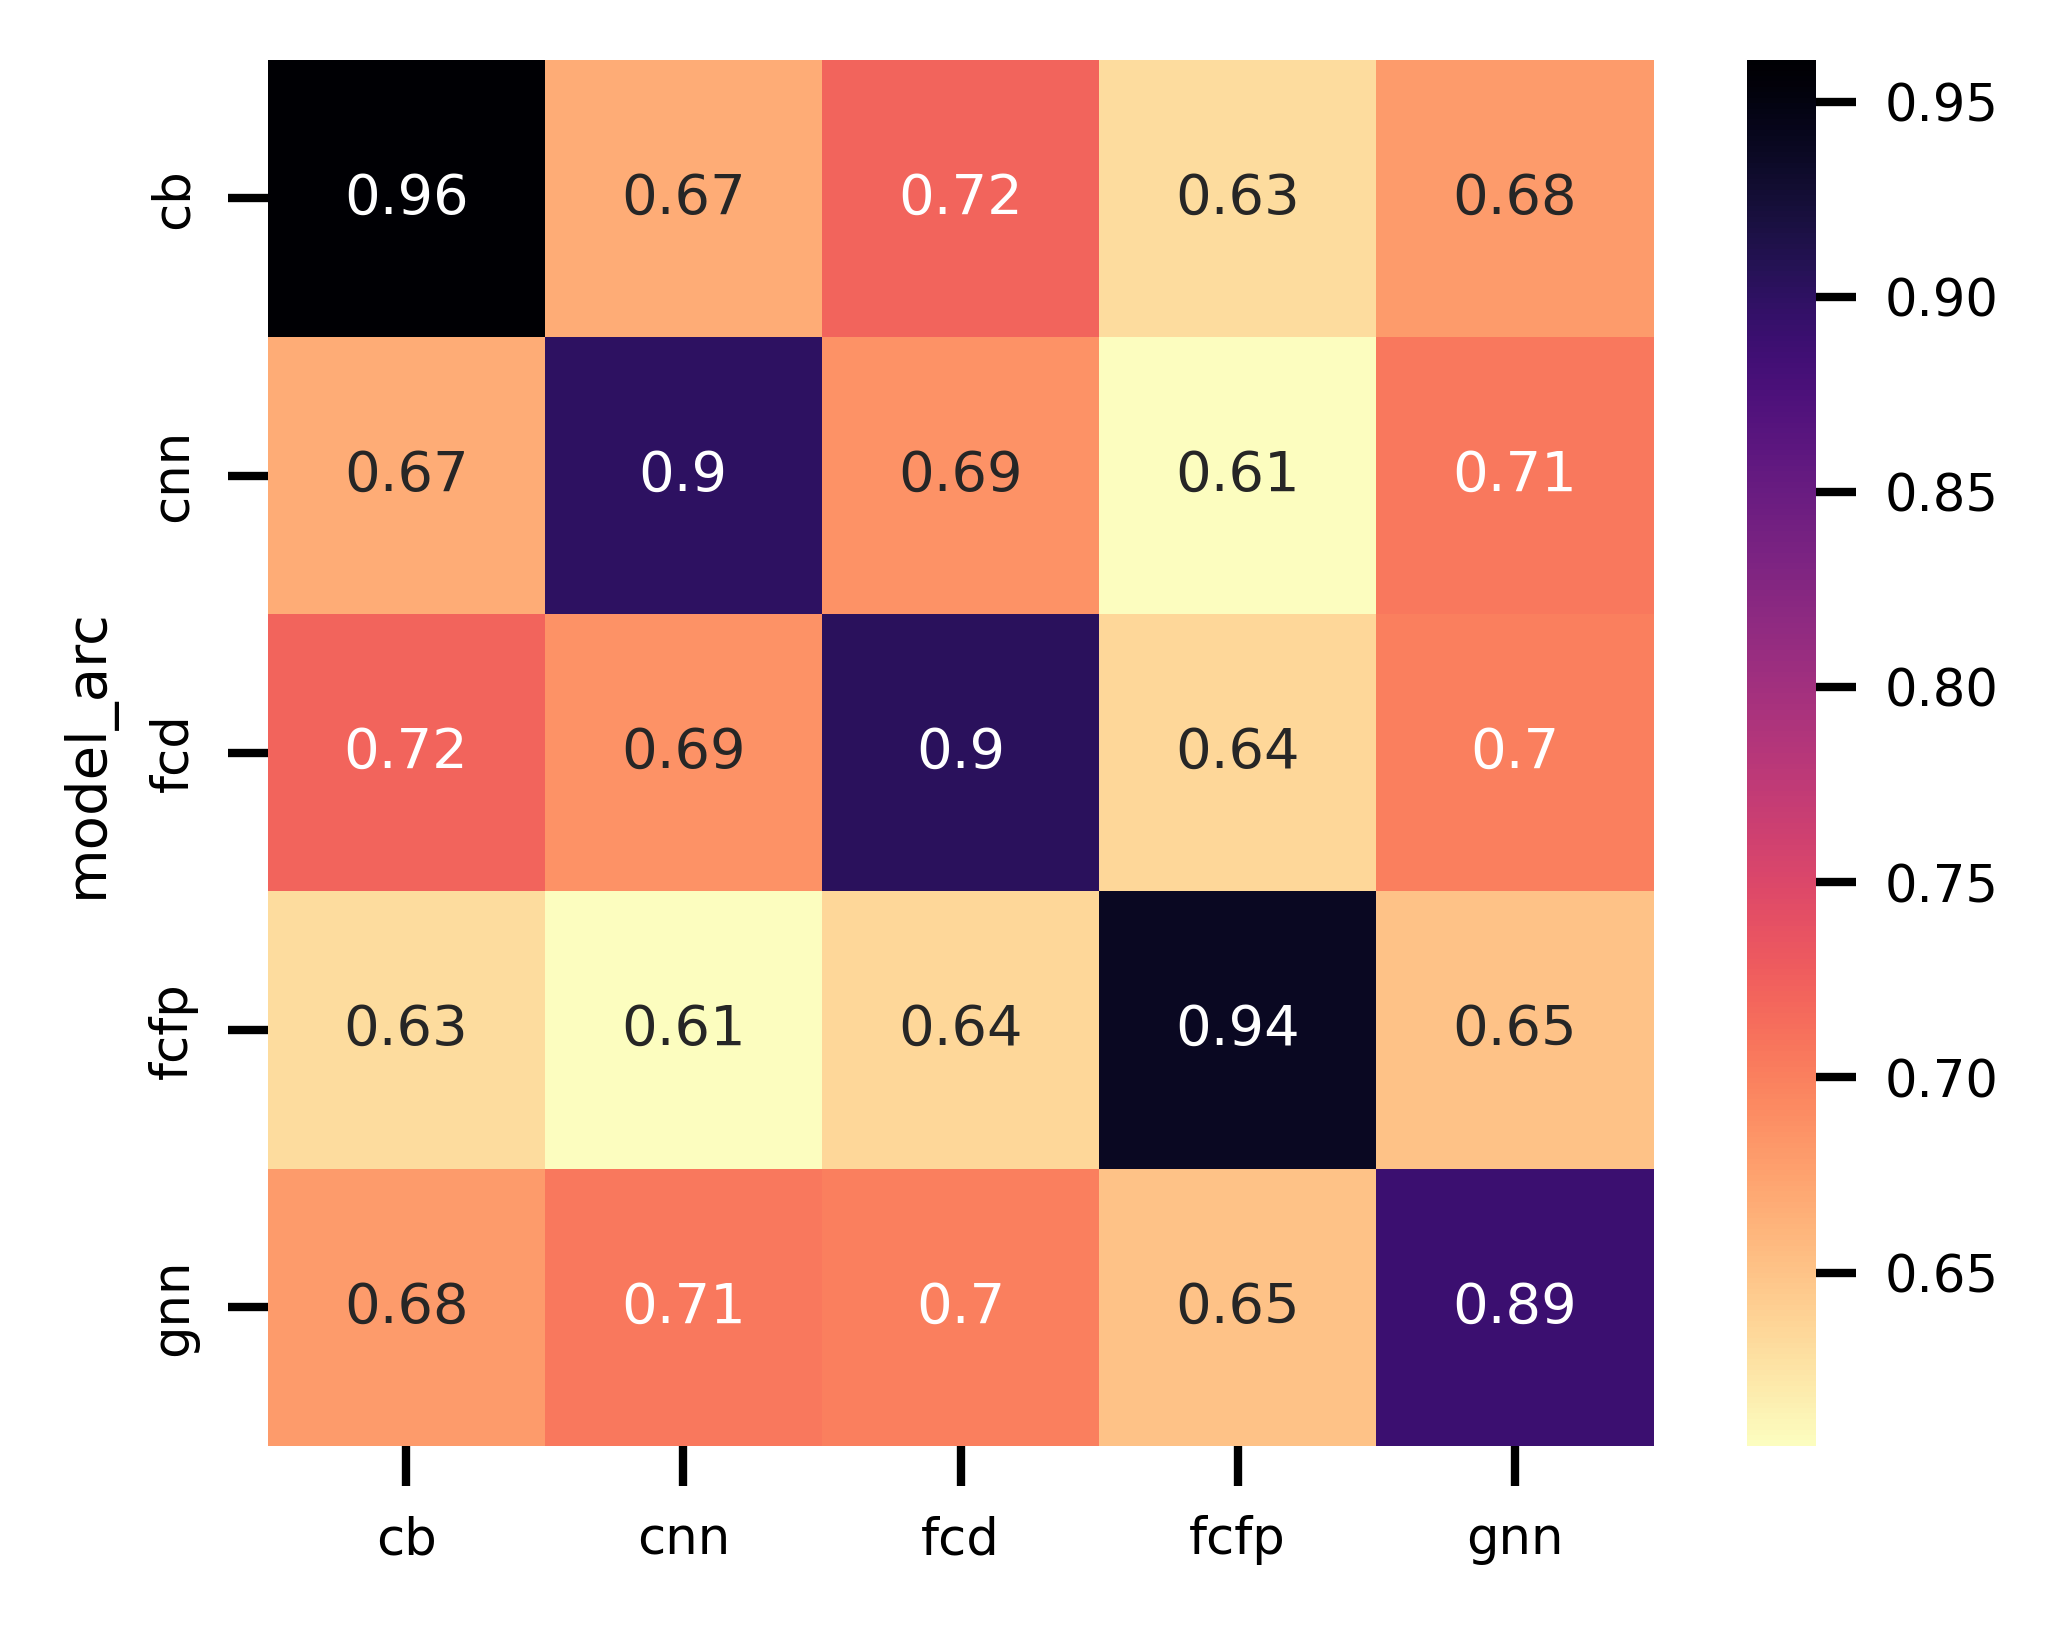

In [34]:
out = {}
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    temp = (
        polar_df[MODEL_NAMES]
        .sub(polar_df["ri"], axis=0)
        .corr()
        .loc[:, [x for x in MODEL_NAMES if model in x]]
        .mean(axis=1)
        .to_frame("corr")
        .reset_index(names=["model"])
    )
    temp["model_arc"] = temp["model"].apply(lambda x: x.split("-")[0])
    out[model] = temp.groupby("model_arc")["corr"].mean().round(4)
out = pd.DataFrame(out)
fg, axs = plt.subplots(1, 1, figsize=(4, 3), dpi=600)
sns.heatmap(
    out,
    annot=True,
    cmap=sns.color_palette("magma_r", as_cmap=True),
    square=True,
    ax=axs,
)

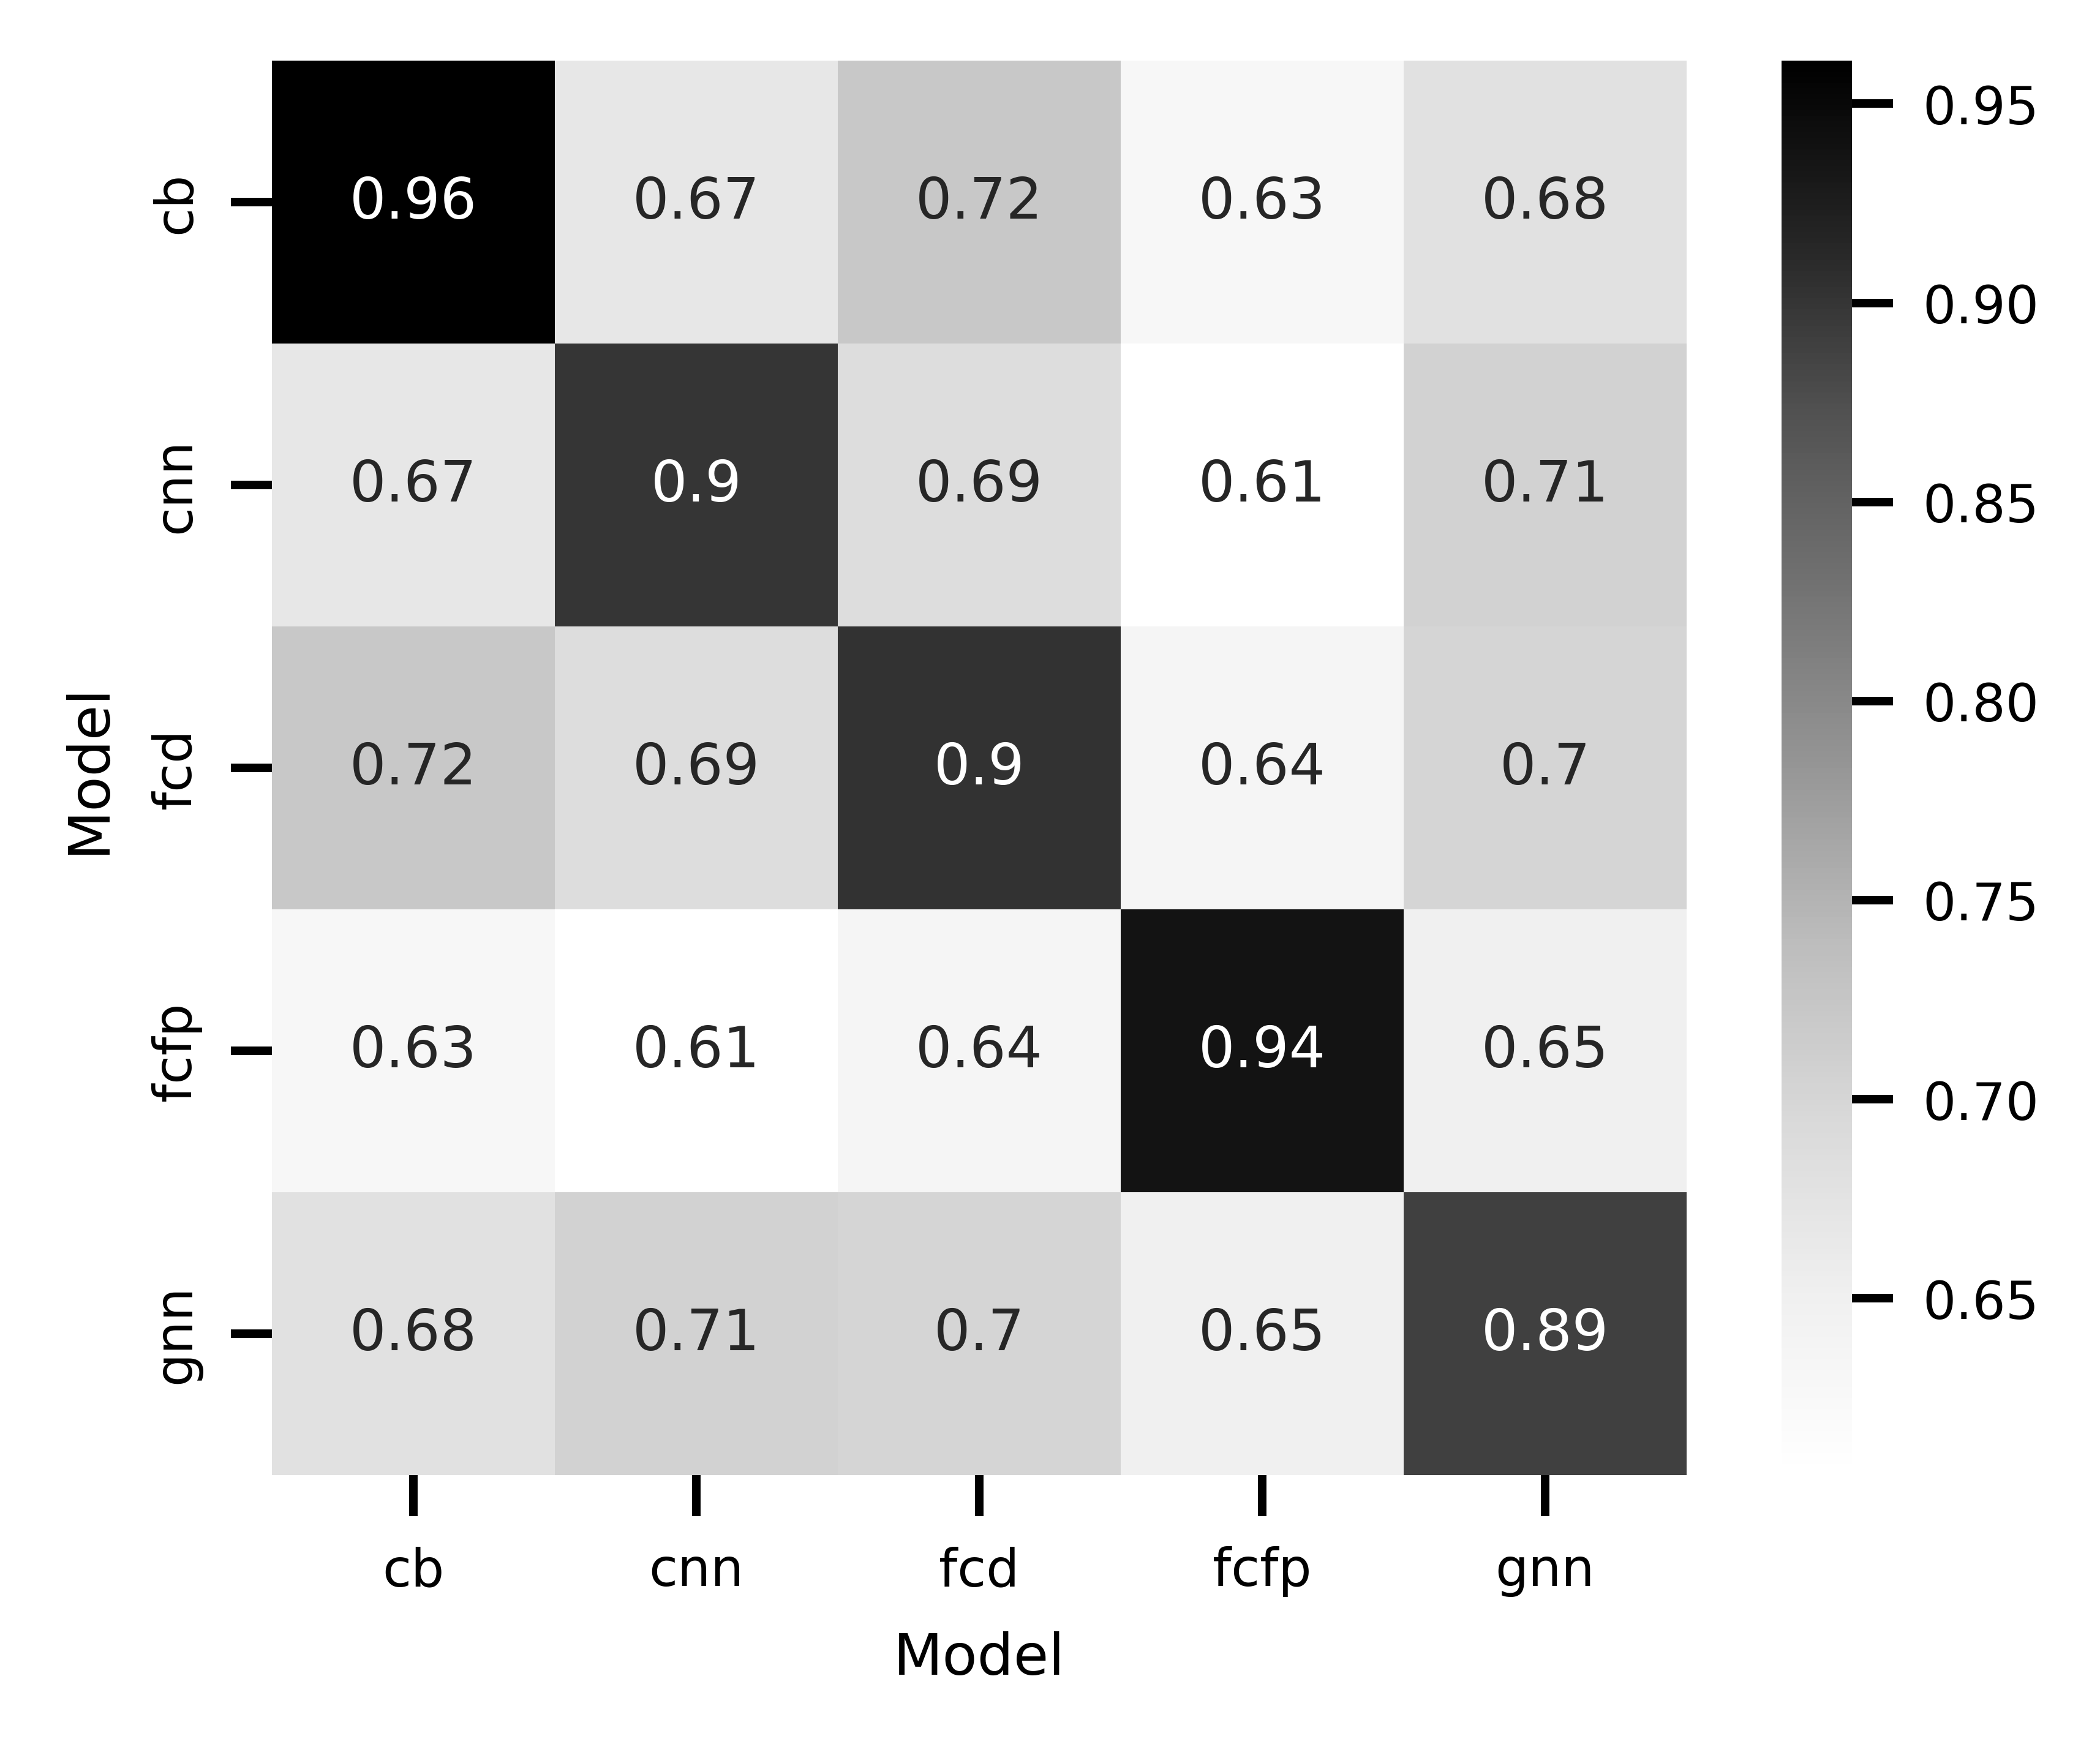

In [37]:
out = {}
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    temp = (
        polar_df[MODEL_NAMES]
        .sub(polar_df["ri"], axis=0)
        .corr()
        .loc[:, [x for x in MODEL_NAMES if model in x]]
        .mean(axis=1)
        .to_frame("corr")
        .reset_index(names=["model"])
    )
    temp["model_arc"] = temp["model"].apply(lambda x: x.split("-")[0])
    out[model] = temp.groupby("model_arc")["corr"].mean().round(4)
out = pd.DataFrame(out)
fg, axs = plt.subplots(1, 1, figsize=(4, 3), dpi=600)
sns.heatmap(
    out,
    annot=True,
    cmap=sns.color_palette("Greys", as_cmap=True),
    square=True,
    ax=axs,
)
axs.set_xlabel("Model")
axs.set_ylabel("Model")
fg.set_dpi(1000)
fg.savefig(BASE_DIR / "reports/figures/Figure_1.tiff", dpi=1000)

Molecule-Phase Error Correlations


<Axes: ylabel='model_arc'>

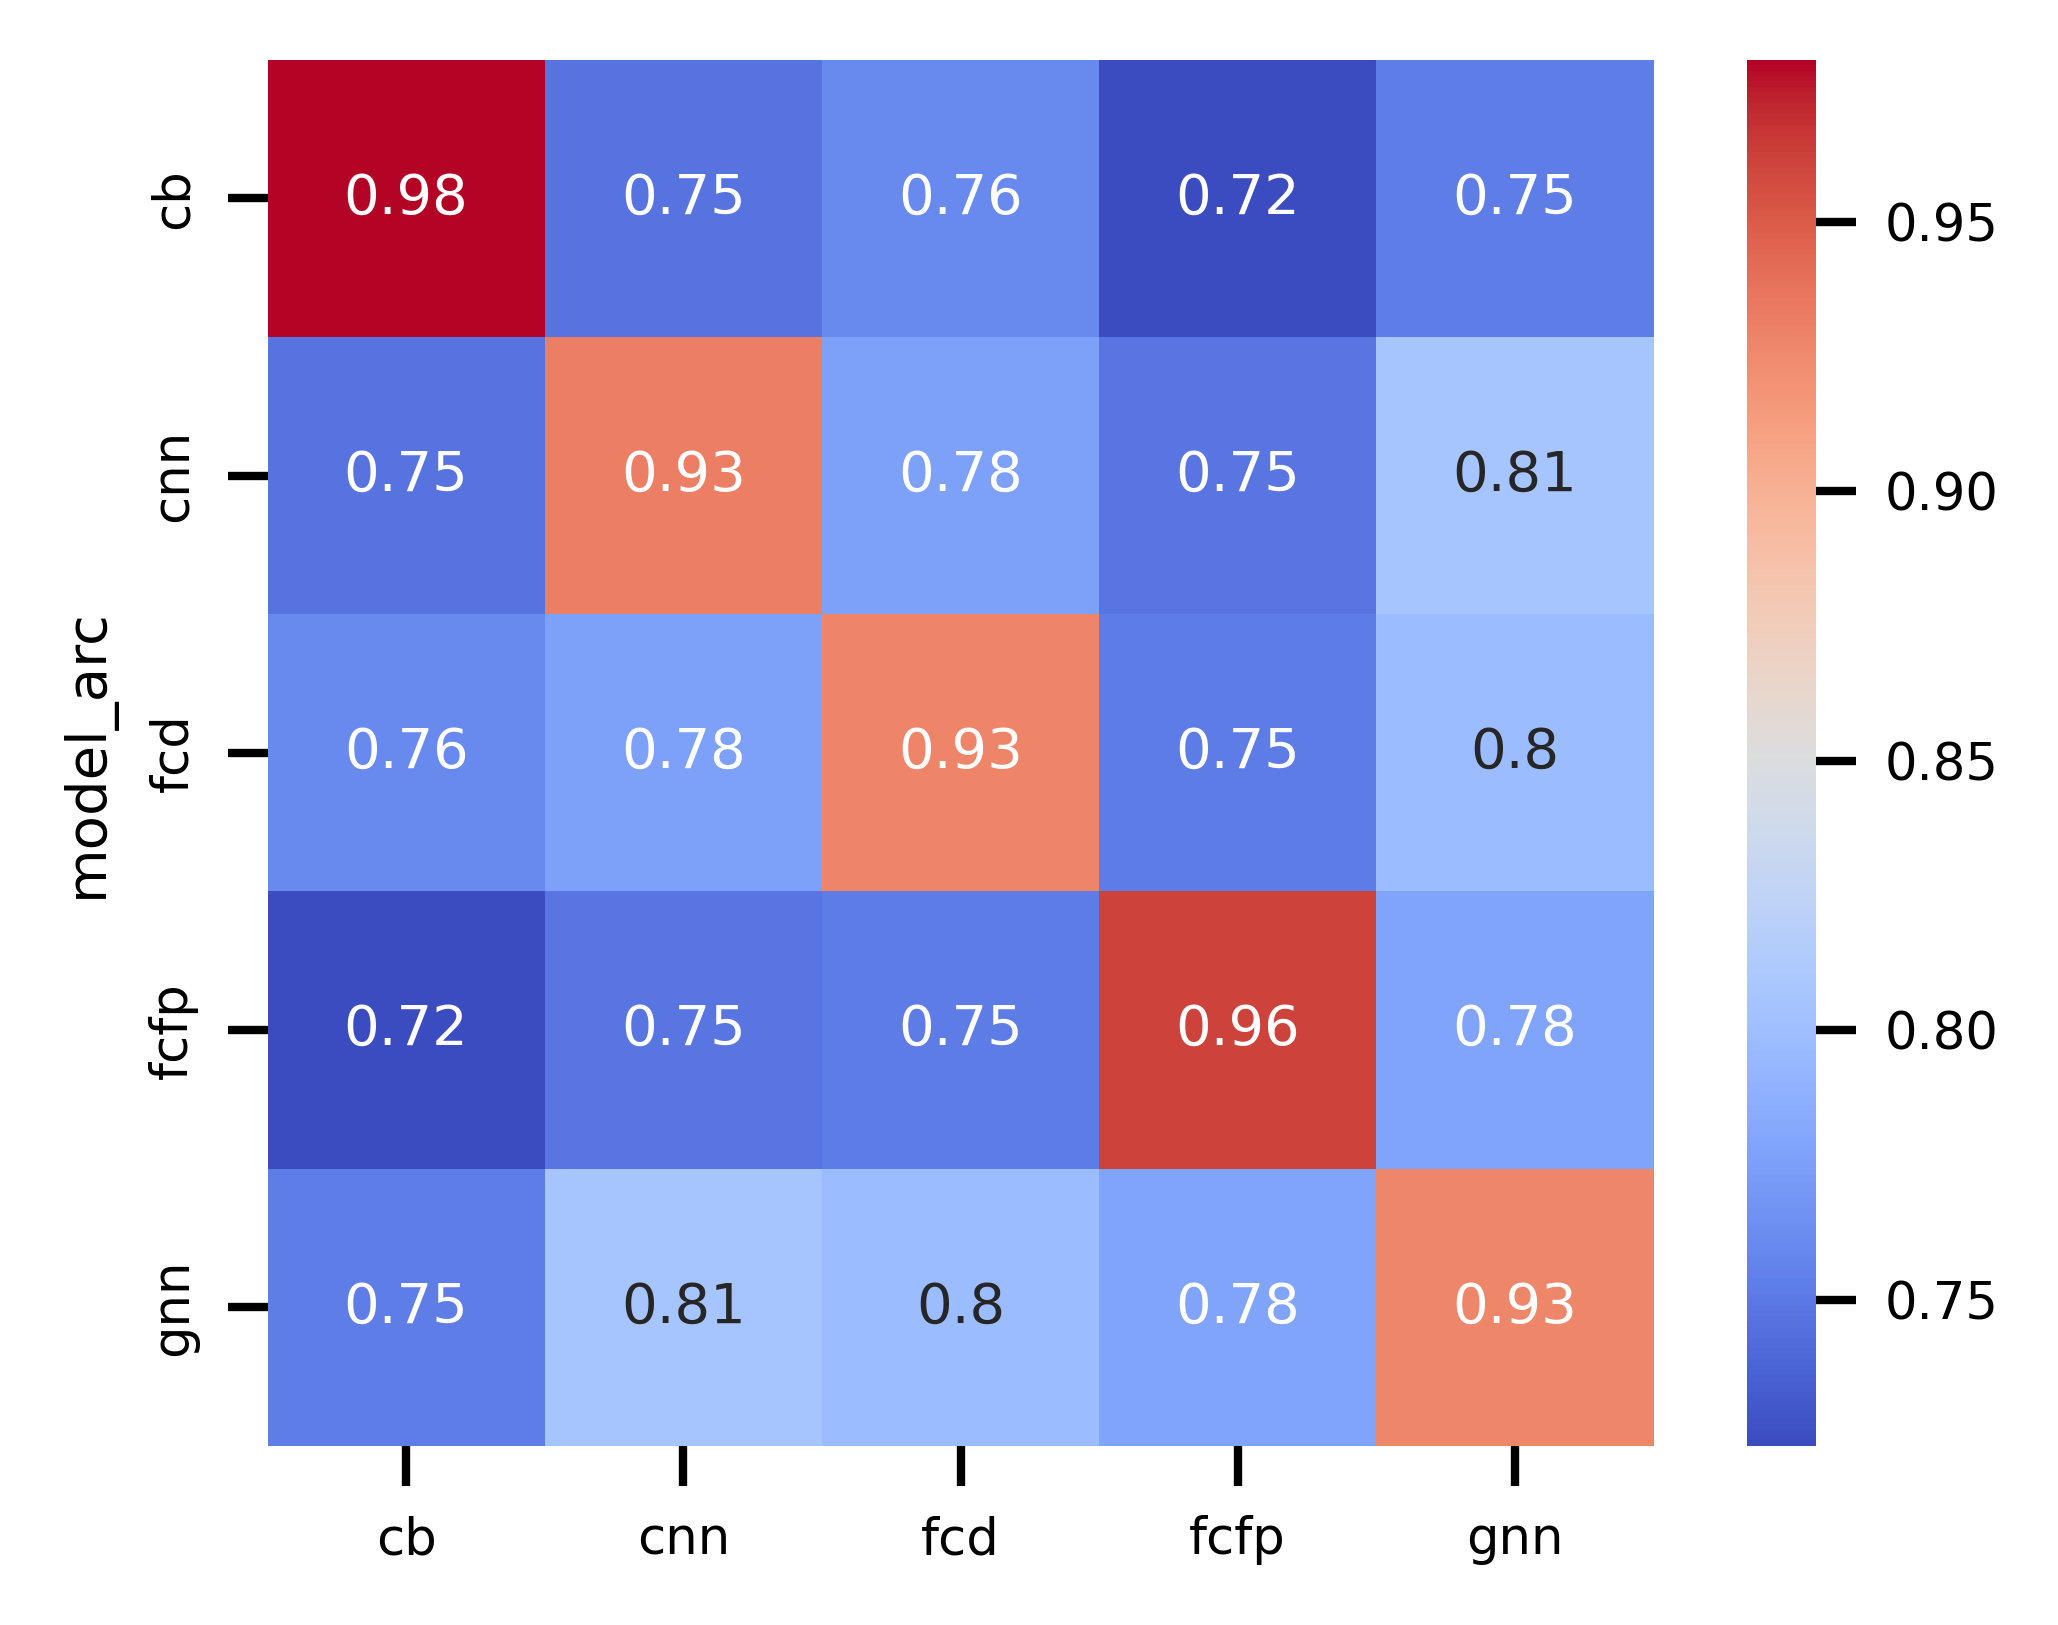

In [ ]:
out = {}
res = polar_df.groupby(["inchikey", "encoded_phases"]).mean(numeric_only=True)
for model in np.unique([x.split("-")[0] for x in MODEL_NAMES]):
    temp = (
        res[MODEL_NAMES]
        .sub(
            res["ri"],
            axis=0,
        )
        .corr()
        .loc[:, [x for x in MODEL_NAMES if model in x]]
        .mean(axis=1)
        .to_frame("corr")
        .reset_index(names=["model"])
    )
    temp["model_arc"] = temp["model"].apply(lambda x: x.split("-")[0])
    out[model] = temp.groupby("model_arc")["corr"].mean().round(4)
out = pd.DataFrame(out)
fg, axs = plt.subplots(1, 1, figsize=(4, 3), dpi=600)
sns.heatmap(
    out,
    annot=True,
    cmap=sns.color_palette("coolwarm", as_cmap=True),
    square=True,
    ax=axs,
)

<Axes: xlabel='model_name', ylabel='model_name'>

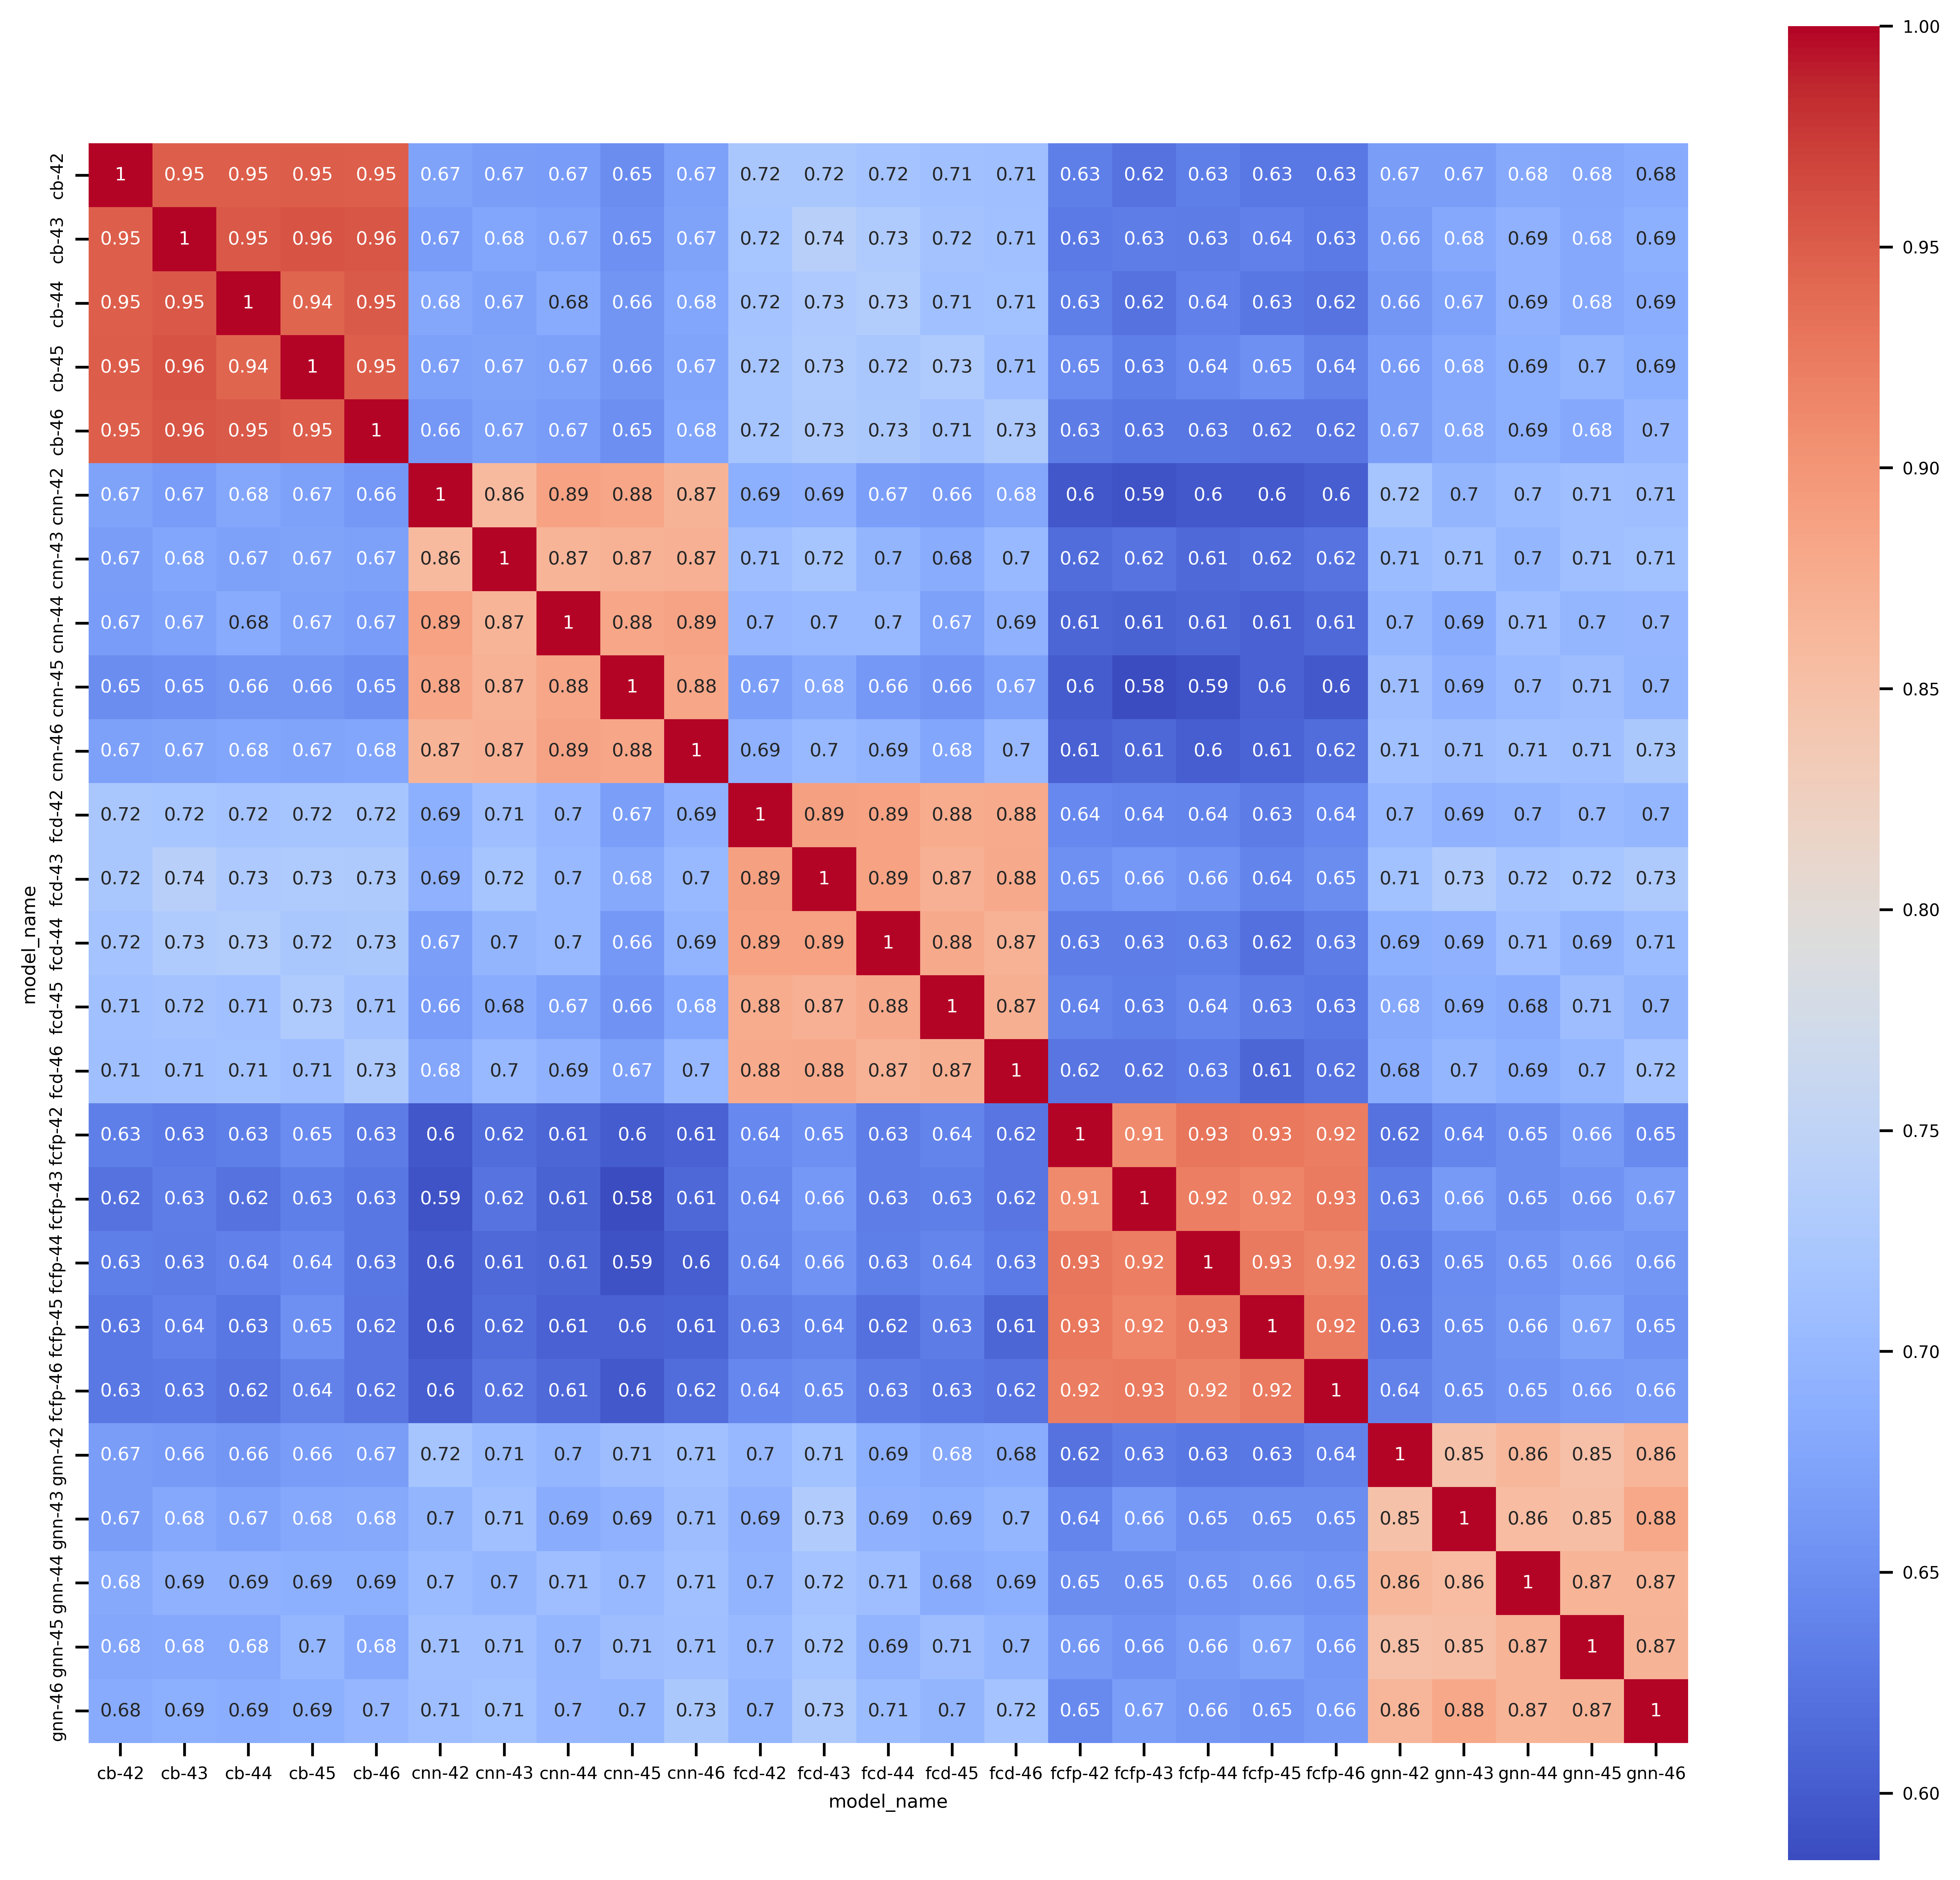

In [97]:
fg, axs = plt.subplots(1, 1, figsize=(13, 12))
sns.heatmap(
    calc_diffs_corrs(
        polar_df,
        model_names=MODEL_NAMES,
        value_name="ri",
    ),
    annot=True,
    cmap=sns.color_palette("coolwarm", as_cmap=True),
    square=True,
    ax=axs,
)

<Axes: xlabel='model_name', ylabel='model_name'>

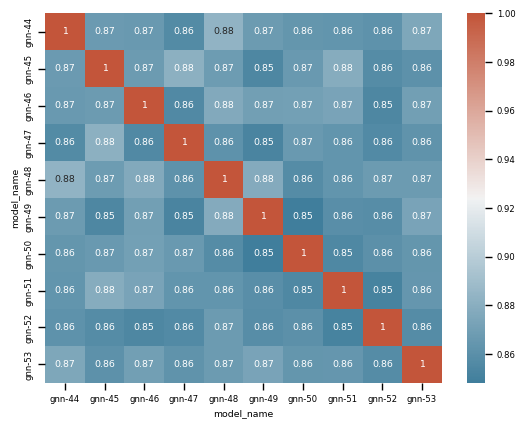

In [ ]:
sns.heatmap(
    calc_diffs_corrs(
        polar_df,
        model_names=GNN_MODELS,
        value_name="ri",
    ),
    annot=True,
    cmap=sns.diverging_palette(230, 20, as_cmap=True),
)

<Axes: xlabel='model_name', ylabel='model_name'>

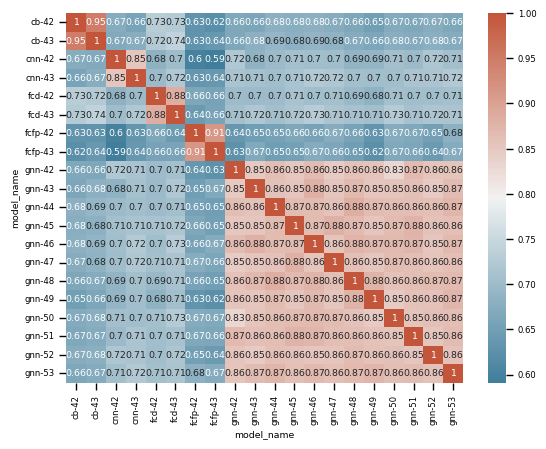

In [ ]:
sns.heatmap(
    calc_diffs_corrs(
        polar_df,
        model_names=GNN_MODELS + MODEL_NAMES,
        value_name="ri",
    ),
    annot=True,
    cmap=sns.diverging_palette(230, 20, as_cmap=True),
)

In [ ]:
calc_diffs_corrs(
    polar_df,
    model_names=MODEL_NAMES,
    value_name="ri",
).mean().sort_values()

model_name
fcfp-42    0.699380
fcfp-43    0.700928
cnn-42     0.717110
gnn-42     0.728148
cnn-43     0.729571
gnn-43     0.731457
cb-42      0.731575
cb-43      0.736466
fcd-42     0.743508
fcd-43     0.749587
dtype: float64

In [ ]:
calc_diffs_corrs(
    polar_df,
    model_names=GNN_MODELS,
    value_name="ri",
).mean().sort_values()

model_name
gnn-52    0.872365
gnn-50    0.875065
gnn-47    0.875475
gnn-49    0.875958
gnn-51    0.877042
gnn-53    0.879368
gnn-45    0.880056
gnn-46    0.880175
gnn-44    0.880382
gnn-48    0.882279
dtype: float64

In [ ]:
calc_diffs_corrs(
    polar_df,
    model_names=MODEL_NAMES + GNN_MODELS,
    value_name="ri",
).mean().sort_values()

model_name
fcfp-43    0.677901
fcfp-42    0.679907
cb-42      0.700512
cb-43      0.707108
cnn-42     0.709117
cnn-43     0.721069
fcd-42     0.722828
fcd-43     0.732212
gnn-49     0.790997
gnn-42     0.791382
gnn-43     0.795484
gnn-52     0.796294
gnn-50     0.798095
gnn-47     0.799404
gnn-48     0.799405
gnn-51     0.799416
gnn-44     0.800037
gnn-45     0.801376
gnn-53     0.802570
gnn-46     0.805145
dtype: float64

In [22]:
calc_diffs_corrs(polar_df, model_names=MODEL_NAMES, value_name="ri")

model_name,cb-42,cb-43,cnn-42,cnn-43,fcd-42,fcd-43,fcfp-42,fcfp-43,gnn-42,gnn-43
model_name,,,,,,,,,,
cb-42,1.000000,0.948173,0.672774,0.656709,0.731294,0.726598,0.629662,0.622782,0.664925,0.662833
cb-43,0.948173,1.000000,0.668649,0.674072,0.724508,0.738074,0.629645,0.638030,0.663262,0.680242
cnn-42,0.672774,0.668649,1.000000,0.852854,0.682224,0.700138,0.597639,0.590991,0.721378,0.684450
cnn-43,0.656709,0.674072,0.852854,1.000000,0.697344,0.721967,0.633587,0.637355,0.713303,0.708517
fcd-42,0.731294,0.724508,0.682224,0.697344,1.000000,0.883873,0.664357,0.656398,0.698560,0.696521
fcd-43,0.726598,0.738074,0.700138,0.721967,0.883873,1.000000,0.642149,0.657276,0.706574,0.719218
fcfp-42,0.629662,0.629645,0.597639,0.633587,0.664357,0.642149,1.000000,0.912523,0.637229,0.647012
fcfp-43,0.622782,0.638030,0.590991,0.637355,0.656398,0.657276,0.912523,1.000000,0.627198,0.666726
gnn-42,0.664925,0.663262,0.721378,0.713303,0.698560,0.706574,0.637229,0.627198,1.000000,0.849054


## Choosing Threshold


In [ ]:
# uc_df = polar_df.copy()
# uc_df["first_threshold"] = -1.0
# for t in tqdm(np.linspace(0, 100, 1001)):
#     groups = calc_groups(dataframe=polar_df, thresholds=t, model_names=MODEL_NAMES, value_name="ri")
#     uc_df.loc[
#         (groups.droplevel(level=["threshold_%","dummy","data_offset"])[f"s_{len(MODEL_NAMES)}_a"] == len(MODEL_NAMES))
#         & (uc_df["first_threshold"] < 0),
#         "first_threshold",
# ] = t
# uc_df.to_parquet(BASE_DIR / "data/processed/25_models_unc.parquet")
uc_df = pd.read_parquet(BASE_DIR / "data/processed/25_models_unc.parquet")

  0%|          | 0/1001 [00:00<?, ?it/s]

In [25]:
results = calc_groups(
    polar_df,
    model_names=MODEL_NAMES,
    thresholds=np.linspace(0, 25, 251),
    value_name="ri",
)
results = (
    results.loc[np.isin(results[f"s_{len(MODEL_NAMES)}_a"], [len(MODEL_NAMES)])]
    .groupby(["threshold_%", f"s_{len(MODEL_NAMES)}_a"])
    .size()
)
# results = (results/len(polar_df)).reset_index()
results = results.reset_index()


In [ ]:
plot_data = results.loc[:, ["threshold_%", 0]]
plot_data = plot_data.rename(columns={0: "Experimental"})

begin_x = plot_data["threshold_%"].to_numpy()
begin_y = plot_data["Experimental"].to_numpy()[begin_x < 2.5]
begin_x = begin_x[begin_x < 2.5]
begin_p = np.polynomial.Polynomial.fit(begin_x, begin_y, 1)
# fg.ax.plot(plot_data["threshold_%"], begin_p(plot_data["threshold_%"]))
plot_data["Approx. beg."] = begin_p(plot_data["threshold_%"])

end_x = plot_data["threshold_%"].to_numpy()
end_y = plot_data["Experimental"].to_numpy()[end_x > 2.5]
end_x = end_x[end_x > 2.5]
end_p = np.polynomial.Polynomial.fit(end_x, end_y, 1)
# fg.ax.plot(plot_data["threshold_%"], end_p(results["threshold_%"]))
plot_data["Approx. end."] = end_p(plot_data["threshold_%"])

plot_data = plot_data.melt(id_vars="threshold_%", var_name="type")
plot_data

,threshold_%,type,value
0,0.1,Experimental,32.000000
1,0.2,Experimental,64.000000
2,0.3,Experimental,88.000000
3,0.4,Experimental,107.000000
4,0.5,Experimental,118.000000
...,...,...,...
745,24.6,Approx. end.,2138.091569
746,24.7,Approx. end.,2145.801223
747,24.8,Approx. end.,2153.510878
748,24.9,Approx. end.,2161.220532


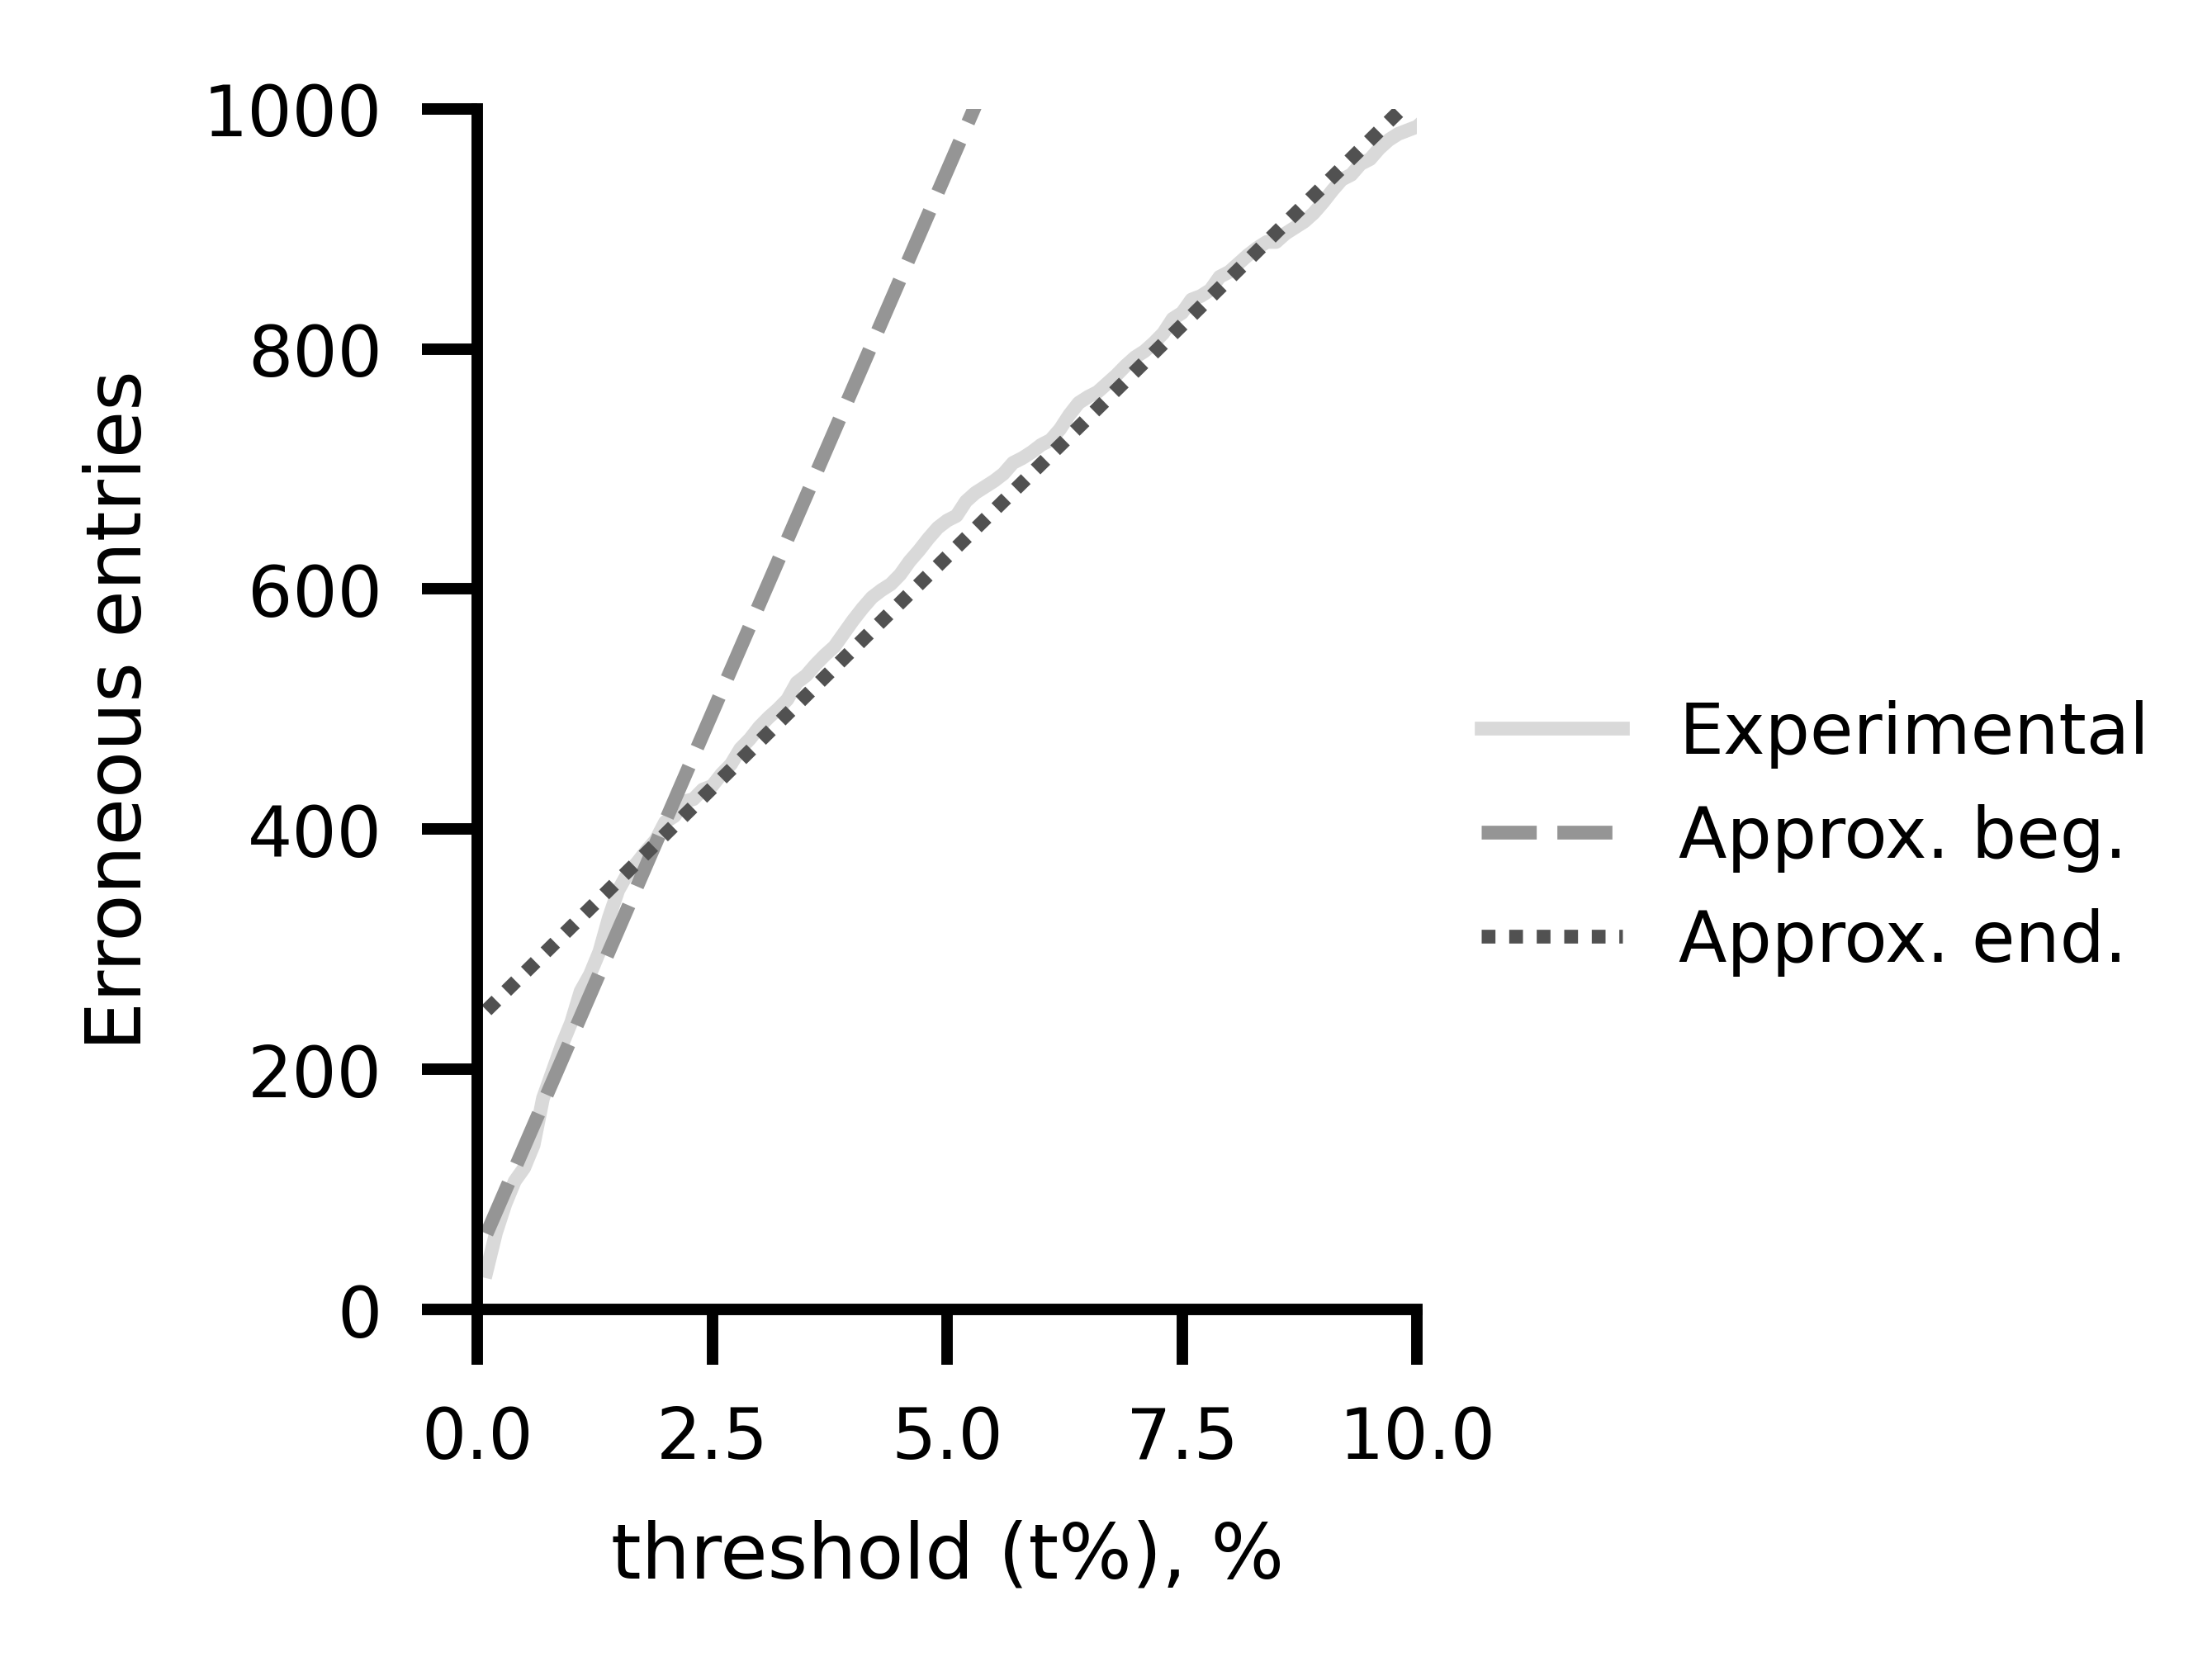

In [36]:
fg = sns.relplot(
    plot_data,
    x="threshold_%",
    y="value",
    hue="type",
    style="type",
    palette="Greys",
    # palette="colorblind_reordered",
    kind="line",
    height=2,
)
# fg.set(yscale="log")
fg.set(xlim=(0, 10))
fg.set(ylim=(0, 1000))
fg.set_xlabels("threshold (t%), %")
fg.set_ylabels("Erroneous entries")
fg.legend.set_title("")
fg.figure.set_dpi(1000)
fg.figure.savefig(BASE_DIR / "reports/figures/Figure_2.tiff", dpi=1000)

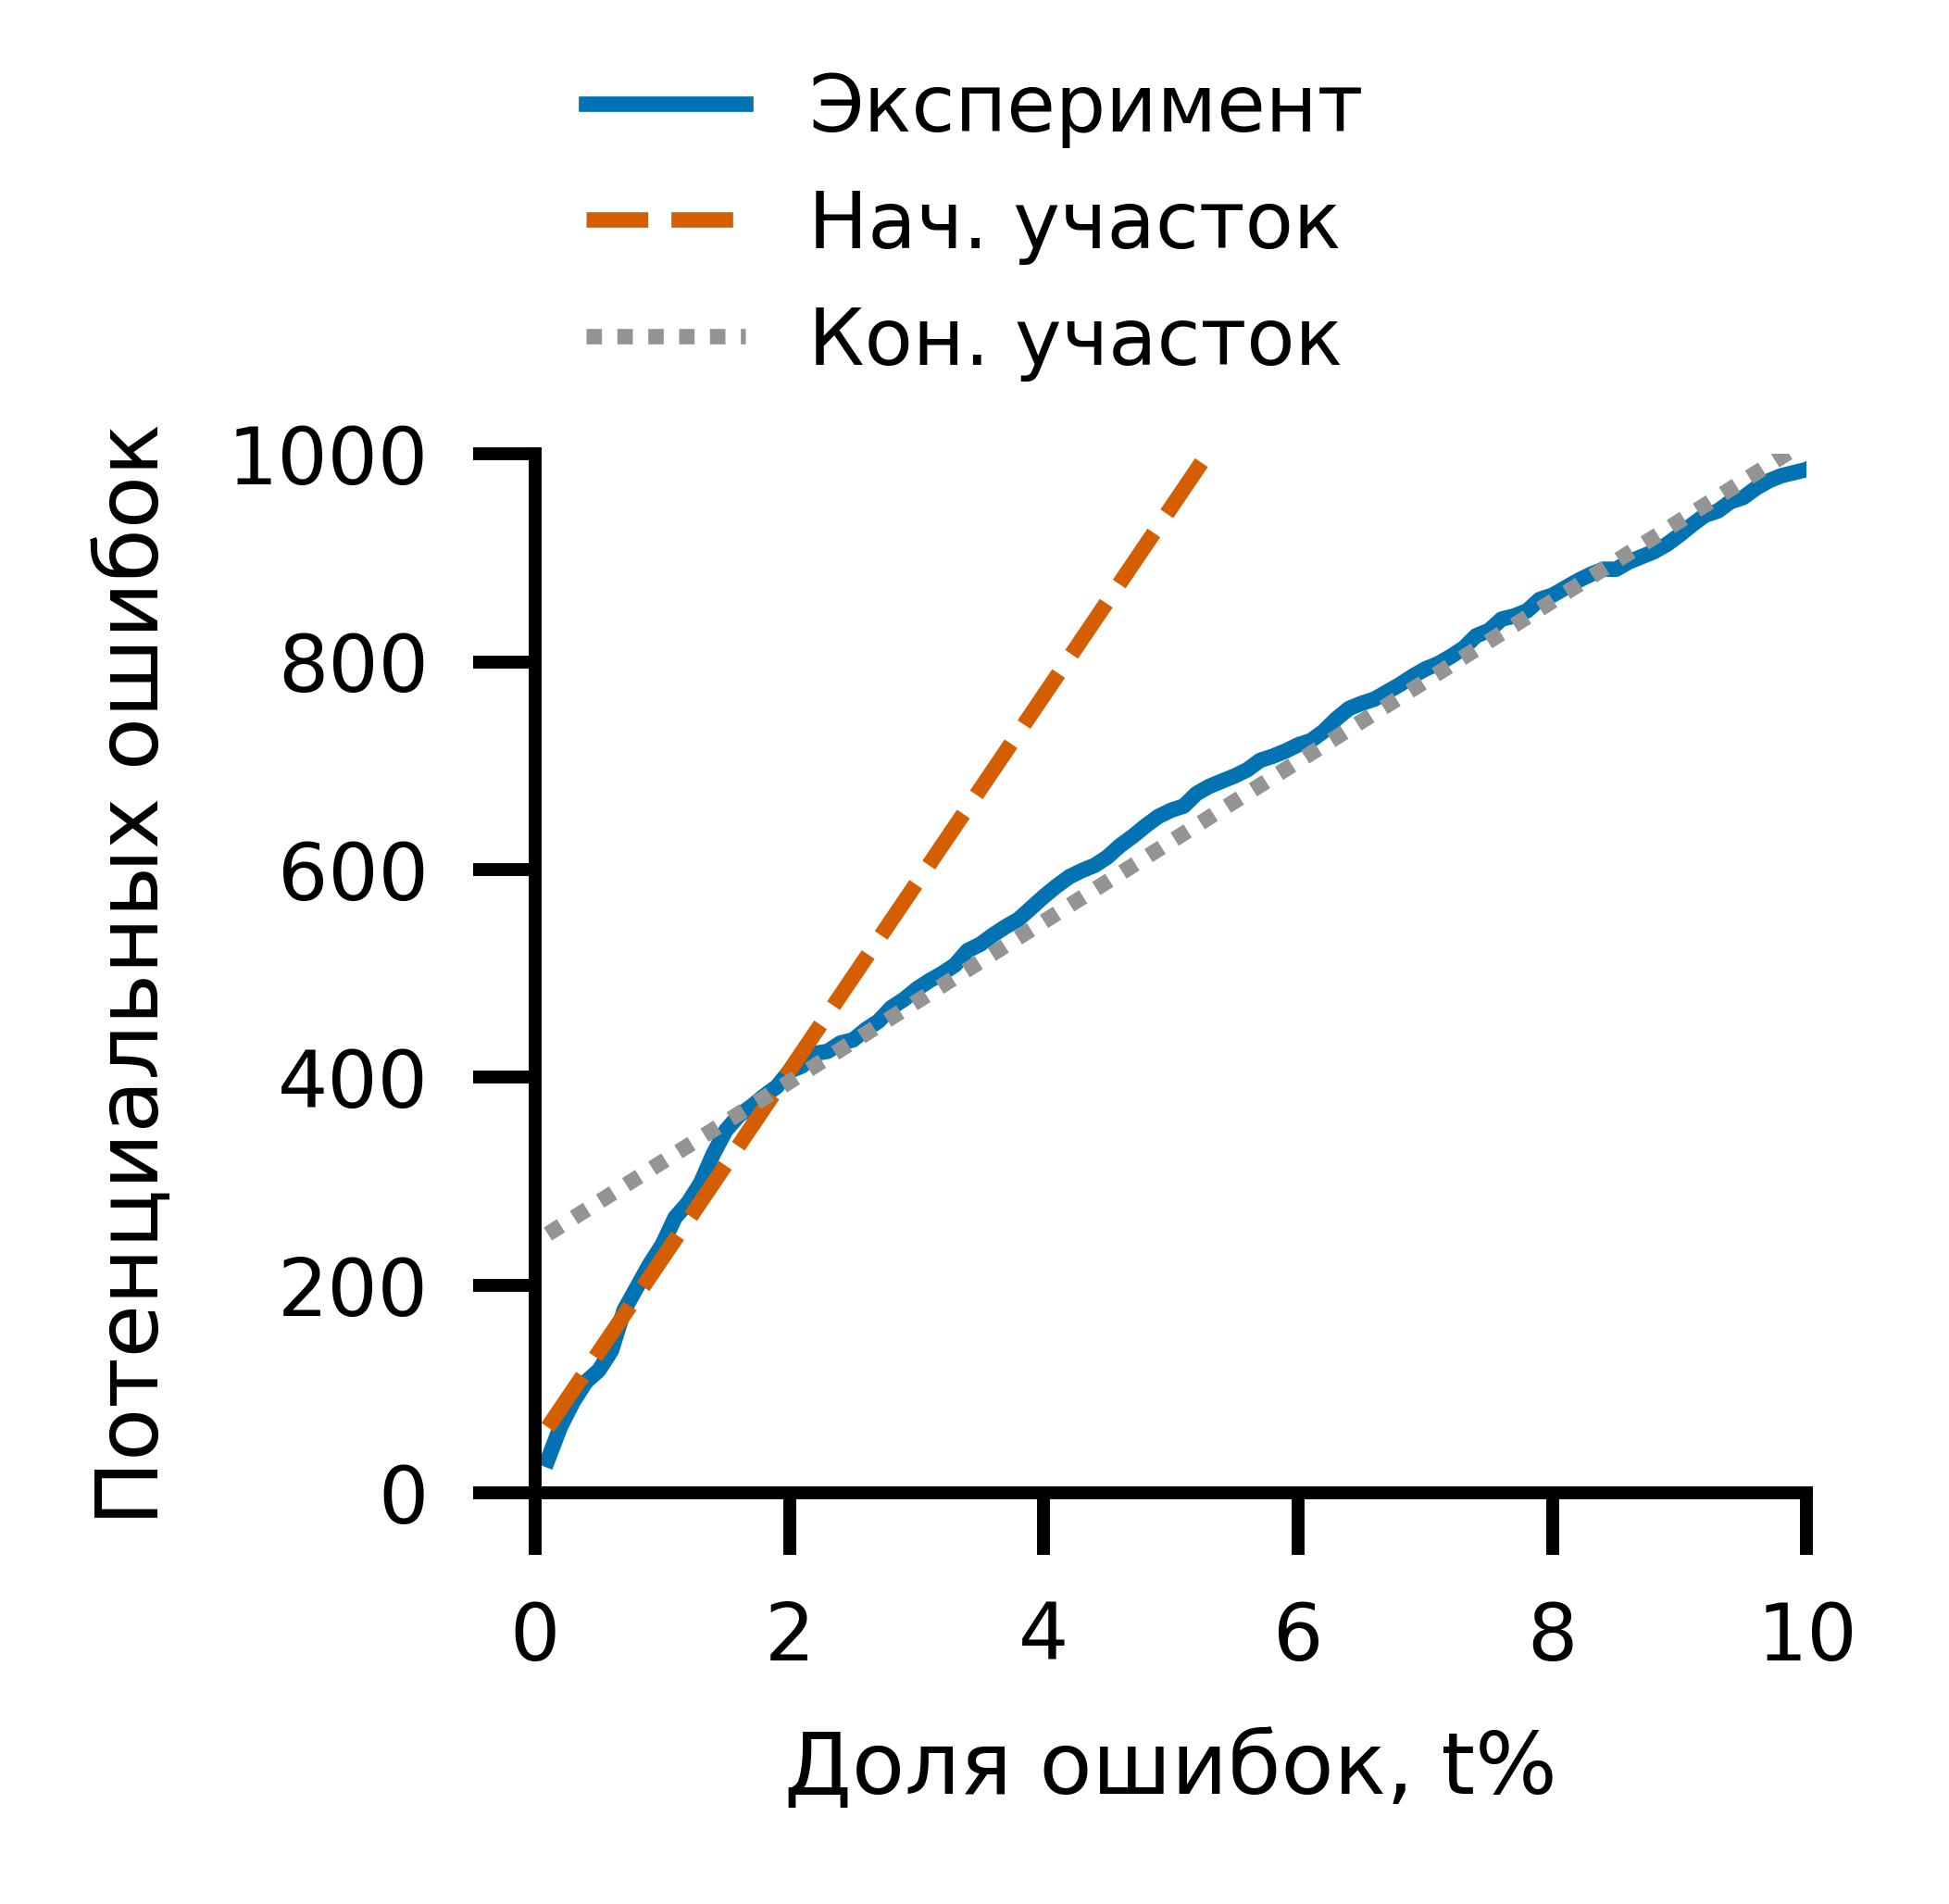

In [47]:
plot_data = results.loc[:, ["threshold_%", 0]]
plot_data = plot_data.rename(columns={0: "Experimental"})

begin_x = plot_data["threshold_%"].to_numpy()
begin_y = plot_data["Experimental"].to_numpy()[begin_x < 2.5]
begin_x = begin_x[begin_x < 2.5]
begin_p = np.polynomial.Polynomial.fit(begin_x, begin_y, 1)
# fg.ax.plot(plot_data["threshold_%"], begin_p(plot_data["threshold_%"]))
plot_data["Approx. beg."] = begin_p(plot_data["threshold_%"])

end_x = plot_data["threshold_%"].to_numpy()
end_y = plot_data["Experimental"].to_numpy()[end_x > 2.5]
end_x = end_x[end_x > 2.5]
end_p = np.polynomial.Polynomial.fit(end_x, end_y, 1)
# fg.ax.plot(plot_data["threshold_%"], end_p(results["threshold_%"]))
plot_data["Approx. end."] = end_p(plot_data["threshold_%"])

plot_data = plot_data.rename(
    columns={
        "Experimental": "Эксперимент",
        "Approx. beg.": "Нач. участок",
        "Approx. end.": "Кон. участок",
    }
).melt(id_vars="threshold_%", var_name="type")


fg = sns.relplot(
    plot_data,
    x="threshold_%",
    y="value",
    hue="type",
    style="type",
    # palette="Greys",
    palette="colorblind_reordered",
    kind="line",
    height=2,
    aspect=0.6,
)
# fg.set(yscale="log")
fg.set(xlim=(0, 10))
fg.set(ylim=(0, 1000))
fg.set_xlabels("Доля ошибок, t%")
fg.set_ylabels("Потенциальных ошибок")
fg.legend.set_title("")
sns.move_legend(fg, "upper center", ncols=1)
fg.tight_layout(rect=(0, 0, 1.0, 0.85))
fg.figure.set_dpi(1000)
fg.figure.savefig(BASE_DIR / "reports/figures/Figure_2_ru.tiff", dpi=1000)

### Check Errors Manually


In [ ]:
results = polar_df.join(
    calc_groups(
        polar_df, MODEL_NAMES, thresholds=np.geomspace(0.5, 100, 101), value_name="ri"
    )
    .droplevel("dummy")
    .join(calc_basic_stats(polar_df, MODEL_NAMES, value_name="ri"))
)

In [ ]:
filtered_results = results.loc[
    ["AVFZOVWCLRSYKC" in x for x in results["inchikey"]], :
]
filtered_results.loc[filtered_results["s_25_a"] == 25]

In [ ]:
filtered_results = results.loc[
    ["NUKYPUAOHBNCPY" in x for x in results["inchikey"]], :
]
filtered_results.loc[filtered_results["s_25_a"] == 25]

In [ ]:
filtered_results = results.loc[
    ["HNOQAFMOBRWDKQ" in x for x in results["inchikey"]], :
]
filtered_results.loc[filtered_results["s_25_a"] == 25]

In [ ]:
filtered_results = results.loc[
    ["QRUDEWIWKLJBPS" in x for x in results["inchikey"]], :
]
filtered_results.loc[filtered_results["s_25_a"] == 25]

In [ ]:
filtered_results = results.loc[
    ["WJNRPILHGGKWCK" in x for x in results["inchikey"]], :
]
filtered_results.loc[filtered_results["s_25_a"] == 25]

In [ ]:
filtered_results = results.loc[
    ["XKVUYEYANWFIJX" in x for x in results["inchikey"]], :
]
filtered_results.loc[filtered_results["s_25_a"] == 25]

In [ ]:
filtered_results = results.loc[
    ["SDXAWLJRERMRKF" in x for x in results["inchikey"]], :
]
filtered_results.loc[filtered_results["s_25_a"] == 15]

In [ ]:
filtered_results = results.loc[
    ["ISPYQTSUDJAMAB" in x for x in results["inchikey"]], :
]
filtered_results.loc[filtered_results["s_25_a"] == 25]

In [ ]:
filtered_results = results.loc[
    ["HORNXRXVQWOLPJ" in x for x in results["inchikey"]], :
]
filtered_results.loc[filtered_results["s_25_a"] == 25]

### Sources (2.5% threshold)


In [ ]:
full_list = polar_df.join(
    calc_groups(polar_df, model_names=MODEL_NAMES, thresholds=2.5, value_name="ri")[
        f"s_{len(MODEL_NAMES)}_a"
    ].droplevel(["dummy", "data_offset"])
)
full_list = full_list.loc[full_list[f"s_{len(MODEL_NAMES)}_a"] == len(MODEL_NAMES), :]
full_list

In [32]:
full_list.columns

Index(['value', 'column_type', 'column_class', 'active_phase', 'column_length',
       'carrier_gas', 'substrate', 'column_diameter', 'phase_thickness',
       'data_type', 'program_type', 'start_t', 'end_t', 'heat_rate',
       'start_time', 'end_time', 'description', 'source', 'inchikey', 'inchi',
       'smiles', 'median_ri_ssnp', 'median_ri_snp', 'median_ri_polar',
       'median_ri_definition', 'estimated_ri_val', 'estimated_ri_ci',
       'estimated_ri_class', 'ai_predicted_ri_val', 'ai_predicted_ri_ci', 'ri',
       'cnn-42', 'cnn-43', 'cnn-44', 'cnn-45', 'cnn-46', 'fcd-42', 'fcd-43',
       'fcd-44', 'fcd-45', 'fcd-46', 'fcfp-42', 'fcfp-43', 'fcfp-44',
       'fcfp-45', 'fcfp-46', 'cb-42', 'cb-43', 'cb-44', 'cb-45', 'cb-46',
       'gnn-42', 'gnn-43', 'gnn-44', 'gnn-45', 'gnn-46', 'encoded_phases',
       's_25_a'],
      dtype='object')

In [ ]:
with pd.option_context("display.max_colwidth", None):
    display(
        full_list.loc[:, ["smiles", "ri", "ai_predicted_ri_val", "source"]]
        .join(
            calc_basic_stats(full_list, MODEL_NAMES, value_name="ri")[
                ["p_median", "d_median_a"]
            ]
        )
        .sort_values("d_median_a")
        .tail(25)
    )

In [31]:
full_list["source"].describe()

count                                                   436
unique                                                  222
top       Welke, J.E.; Manfroi, V.; Zanus, M.; Lazarotto...
freq                                                     34
Name: source, dtype: object

#### Most Prominent


In [27]:
full_list.groupby("source").size().sort_values(ascending=False).head(20).to_frame()

,0
source,
"Welke, J.E.; Manfroi, V.; Zanus, M.; Lazarotto, M.; Zini, C.A., Characterization of the volatile profile of Brazilian merlot wines through comprehensive two dimensional gas chromatography time-of-flight mass spectrometric detection, J. Chromatogr. A, 1226, 2012, 124-139.",34
"Reboucas, L.M.; Sant-Ana, A.E.G.; Griepink, F.C., Kovats retention indexes of mono- and di-unsaturated C18 alcohols, acetates and aldehydes found in Lepidopteran pheromone blends, in XVI International Plant Protection Congress. Congress Proceedings. Vol.2, Scottish Exhibition and Conference Centre, Glagow, Scotland, UK, 15-18 October, 2007, 2007, 590-591.",32
"Kiss, M.; Csoka, M.; Gyorfi, J.; Korany, K., Comparison of the fragrance constituents of Tuber aestivium and Tuber Brumale gathered in Hungary, J. Appl. Botany Food Quality, 84, 2011, 102-110.",9
"Pontes, M.; Marques, J.C.; Camara, J.S., Screening of volatile composition from Portuguese multifloral honeys using headspace solid-phase microextraction-gas chromatography-quadrupole mass spectrometry, Talanta, 74, 2007, 91-103.",6
"Kim. J.H.; Ahn, H.J.; Yook, H.S.; Kim, K.S.; Rhee, M.S.; Ryu, G.H.; Byun, M.W., Color, flavor, and sensory characteristics of gamma-irradiated salted and fermented anchovy sauce, Radiation Phys. Chem., 69, 2004, 179-187.",6
"Budryn, G.; Nebesny, E.; Kula, J.; Majda, T.; Krysiak, W., HS-SPME/GC/MS Profiles of convectively and microwave roasted Ivory Coast Robusta coffee brews, Czech. J. Food Sci., 29(2), 2011, 151-160.",6
"Nebesny, E.; Budryn, G.; Kula, J.; Majda, T., The effect of roasting method on headspace composition of robusta coffee bean aroma, Eur. Food Res. Technol., 225, 2007, 9-19.",6
"Shimoda, M.; Shigematsu, H.; Shiratsuchi, H.; Osajima, Y., Comparison of the odor concentrates by SDE and adsorptive column method from green tea infusion, J. Agric. Food Chem., 43, 1995, 1616-1620.",5
"Rawat, R.; Gulati, A.; Babu, G.D.K.; Acharya, R.; Kaul, V.K.; Singh, B., Characterization of volatile components of Kangra orthodox black tea by gas chromatography-mass spectrometry, Food Chem., 105, 2007, 229-235.",5


#### First Case (Welke et al.)


In [ ]:
full_list.loc[
    full_list["source"]
    == full_list.groupby("source")
    .size()
    .sort_values(ascending=False)
    .reset_index()
    .loc[0, "source"]
]

In [41]:
polar_df.groupby("column_length").size()

column_length
0 m       61
0.5 m      2
1 m      124
1.2 m     24
1.3 m     20
        ... 
70 m     106
75 m      82
80 m     749
85 m     154
90 m      38
Length: 72, dtype: int64

In [40]:
polar_df.loc[polar_df["encoded_phases"] == 43].groupby("column_length").size()

column_length
0 m        25
10 m        9
15 m      357
20 m      123
25 m      184
27 m        2
30 m    11614
50 m       81
60 m    10381
dtype: int64

In [ ]:
polar_df.loc[
    polar_df["source"]
    == full_list.groupby("source")
    .size()
    .sort_values(ascending=False)
    .reset_index()
    .loc[0, "source"]
]

In [ ]:
temp = polar_df.join(
    calc_groups(polar_df, MODEL_NAMES, value_name="ri", thresholds=2.5).droplevel(
        ["dummy", "threshold_%", "data_offset"]
    )
).join(calc_basic_stats(polar_df, MODEL_NAMES, value_name="ri"))
temp = temp.loc[
    temp["source"]
    == full_list.groupby("source")
    .size()
    .sort_values(ascending=False)
    .reset_index()
    .loc[0, "source"],
    [
        "smiles",
        "value",
        "ri",
        "p_median",
        "d_median_a",
        "encoded_phases",
        f"s_{len(MODEL_NAMES)}_a",
    ],
]
temp = temp.loc[temp[f"s_{len(MODEL_NAMES)}_a"] == len(MODEL_NAMES), :].sort_values(
    "ri"
)
temp

In [ ]:
temp = polar_df.join(
    calc_groups(polar_df, MODEL_NAMES, value_name="ri", thresholds=2.5).droplevel(
        ["dummy", "threshold_%", "data_offset"]
    )
).join(calc_basic_stats(polar_df, MODEL_NAMES, value_name="ri"))
temp = temp.loc[
    temp["source"]
    == full_list.groupby("source")
    .size()
    .sort_values(ascending=False)
    .reset_index()
    .loc[0, "source"],
    [
        "smiles",
        "ri",
        "value",
        "p_median",
        "d_median_a",
        "p_std",
        "gnn-42",
        "encoded_phases",
        f"s_{len(MODEL_NAMES)}_a",
    ],
]
temp = temp.loc[temp[f"s_{len(MODEL_NAMES)}_a"] == len(MODEL_NAMES), :].sort_values(
    "ri"
)
temp

#### Second Case (Reboucas et al.)


In [ ]:
polar_df.loc[polar_df["encoded_phases"] == 48]

In [ ]:
polar_df.loc[polar_df["active_phase"].str.lower() == "at-wax"]

In [ ]:
polar_df.loc[polar_df["active_phase"].str.lower() == "at-wax"][
    "column_length"
].describe()

count      956
unique       2
top       60 m
freq       916
Name: column_length, dtype: object

In [42]:
polar_df.loc[polar_df["encoded_phases"] == 48].groupby("column_length").size()

column_length
15 m     126
20 m      36
25 m     364
30 m    3797
50 m    1977
60 m    5175
dtype: int64

In [ ]:
polar_df.loc[polar_df["smiles"] == r"CCCCCCCC/C=C\CCCCCCCCO"]

<Axes: >

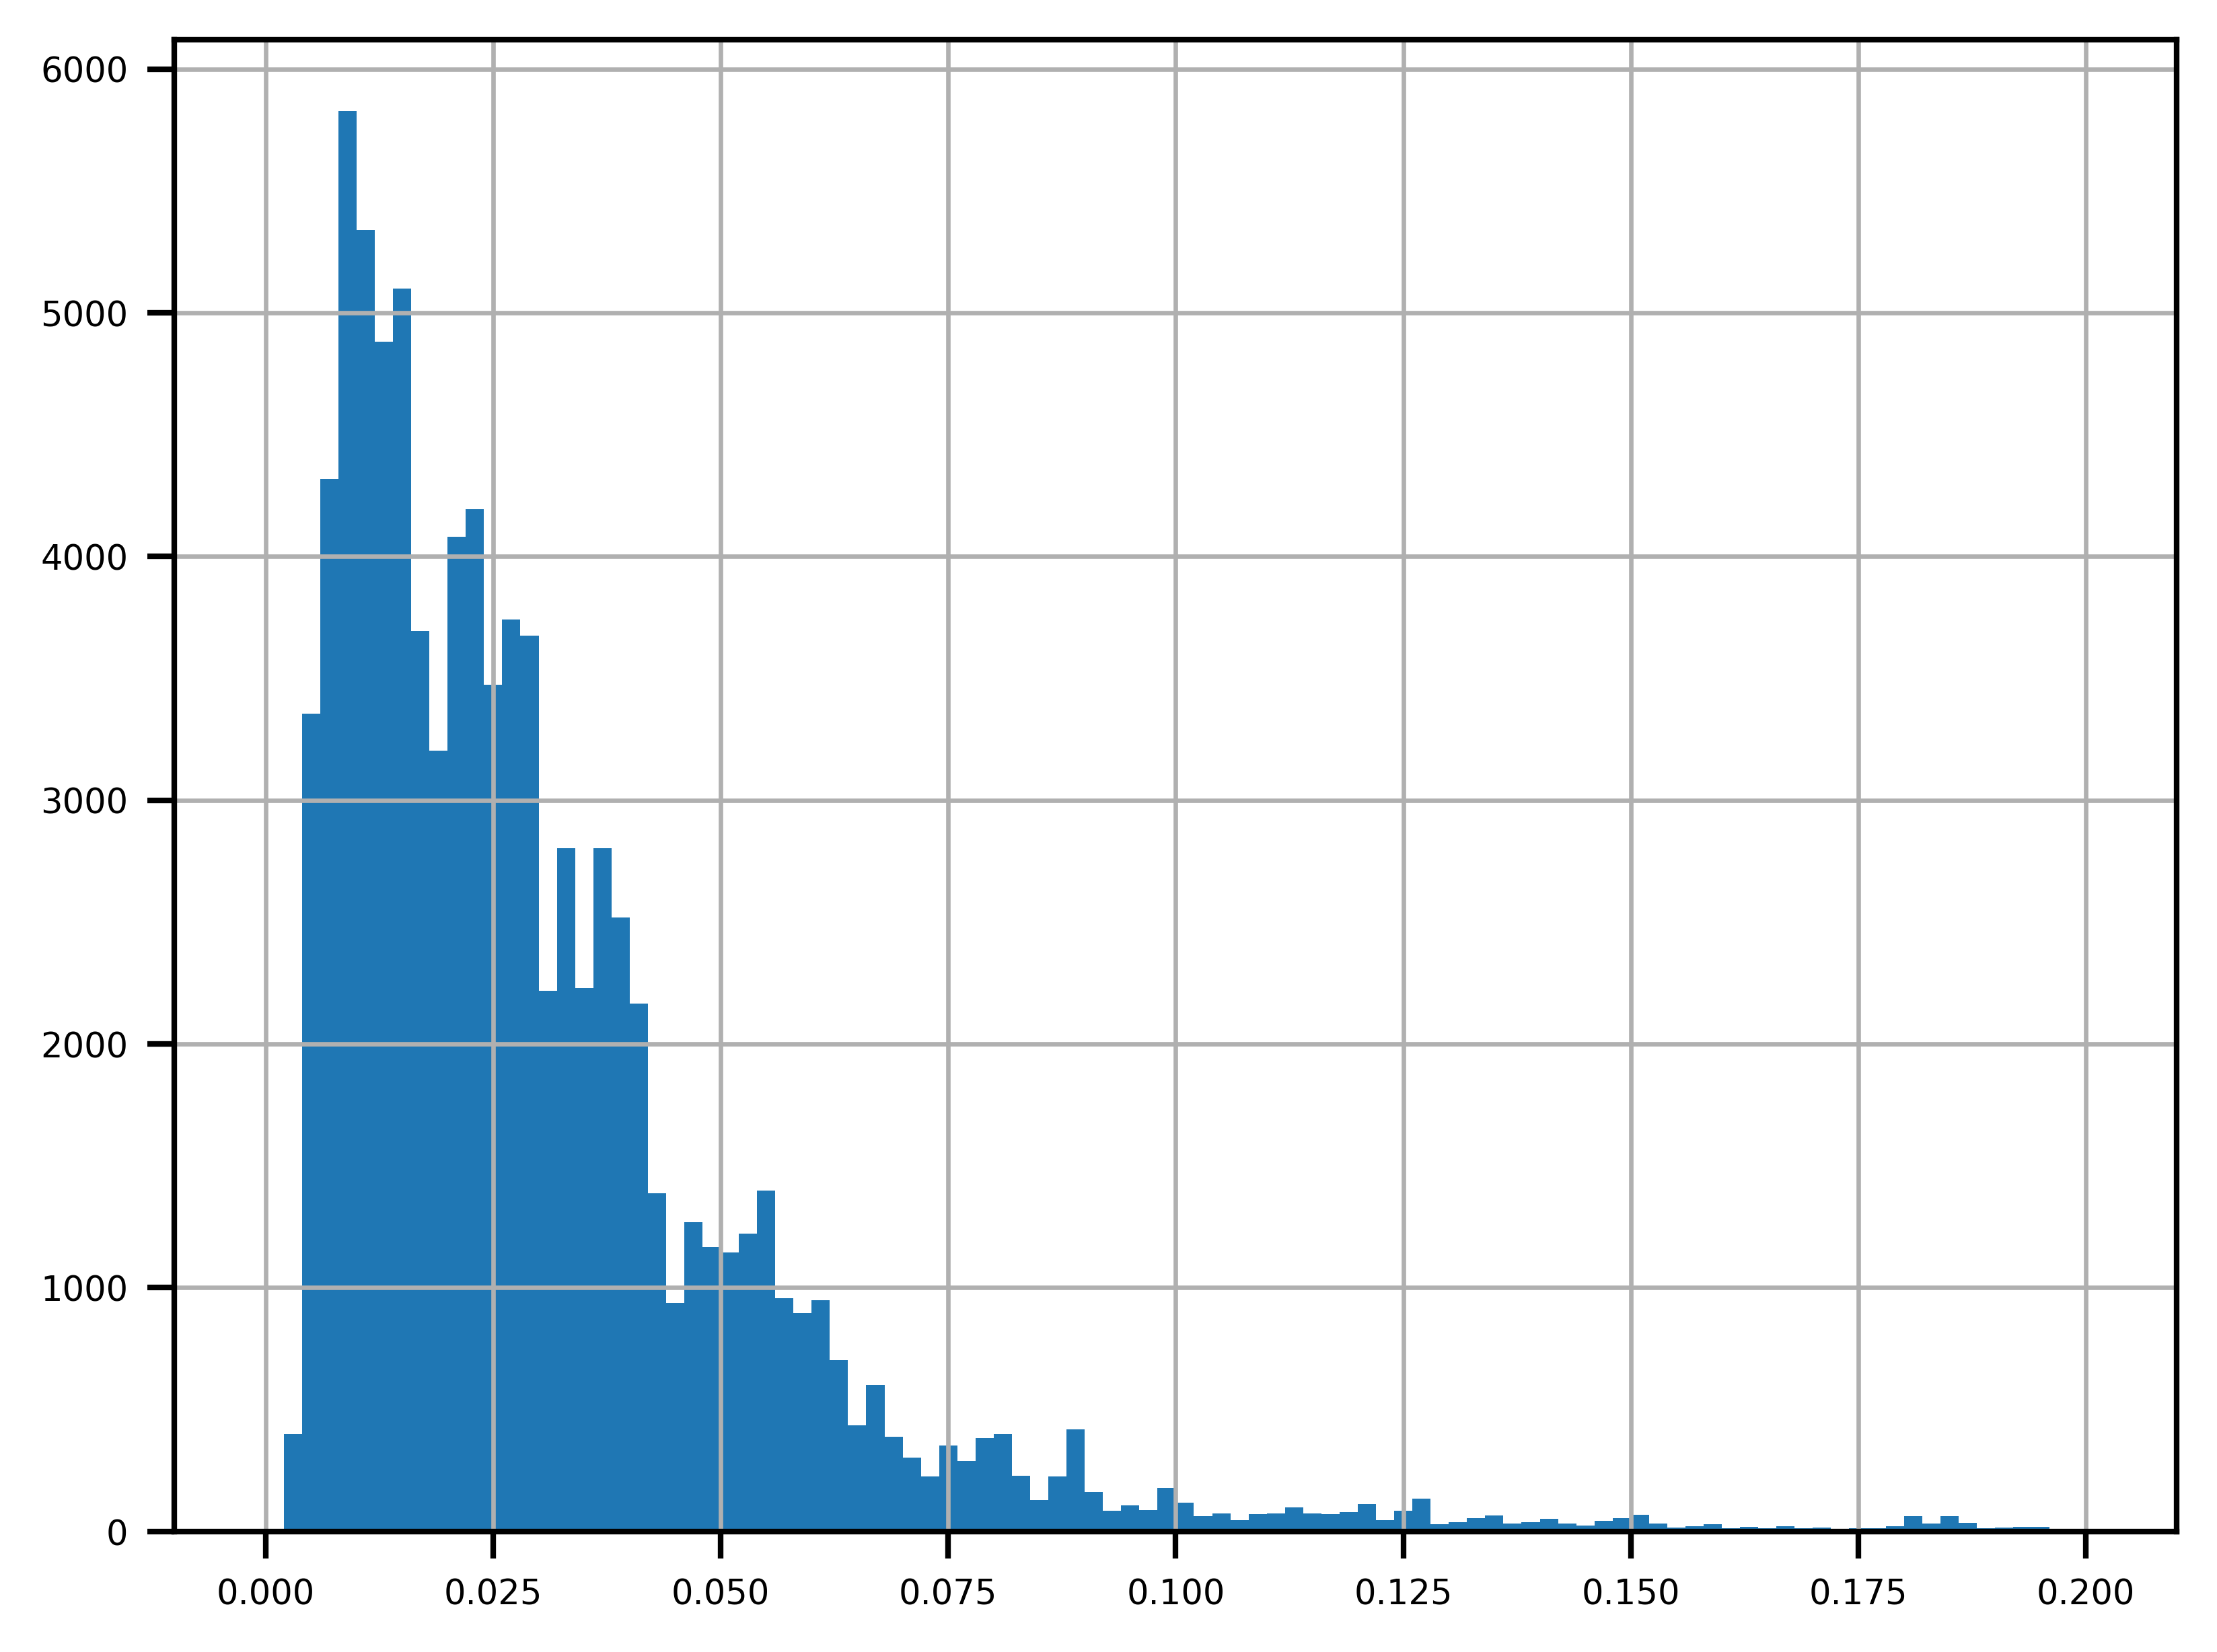

In [ ]:
polar_df.join(calc_basic_stats(polar_df, MODEL_NAMES, value_name="ri"))["p_std"].hist(
    bins=np.linspace(0, 0.2, 101)
)

In [ ]:
polar_df.join(calc_basic_stats(polar_df, MODEL_NAMES, value_name="ri"))[
    "p_std"
].describe()

count    89469.000000
mean         0.031259
std          0.027801
min          0.003034
25%          0.013325
50%          0.024302
75%          0.039020
max          0.793873
Name: p_std, dtype: float64

In [ ]:
polar_df.join(calc_basic_stats(polar_df, MODEL_NAMES, value_name="ri")).loc[
    polar_df["source"]
    == full_list.groupby("source")
    .size()
    .sort_values(ascending=False)
    .reset_index()
    .loc[1, "source"],
    [
        "smiles",
        "value",
        "p_median",
        "d_median_a",
        "p_std",
        "active_phase",
        "column_length",
        "column_diameter",
        "data_type",
        "program_type",
        "start_t",
        "end_t",
        "heat_rate",
        "start_time",
        "end_time",
        "description",
        "encoded_phases",
    ],
]

In [53]:
polar_df.join(calc_basic_stats(polar_df, MODEL_NAMES, value_name="ri")).loc[
    polar_df["source"]
    == full_list.groupby("source")
    .size()
    .sort_values(ascending=False)
    .reset_index()
    .loc[1, "source"],
    [
        "smiles",
        "value",
        "p_median",
        "d_median_a",
        "p_std",
        "active_phase",
        "column_length",
        "column_diameter",
        "data_type",
        "program_type",
        "start_t",
        "end_t",
        "heat_rate",
        "start_time",
        "end_time",
        "description",
        "encoded_phases",
    ],
].describe()

,p_median,d_median_a,p_std,encoded_phases
count,37.000000,37.000000,37.000000,37.0
mean,2.561804,0.461074,0.034824,48.0
std,0.047525,0.011385,0.016720,0.0
min,2.484220,0.439870,0.011883,48.0
25%,2.524490,0.452500,0.023095,48.0
50%,2.571810,0.459490,0.032628,48.0
75%,2.600060,0.466130,0.037449,48.0
max,2.643500,0.489840,0.080635,48.0


## Check Laboratory Data


In [ ]:
err_df = pd.read_csv(BASE_DIR / "data/input/check_laboratory.csv", sep=";").dropna()
err_df

In [160]:
uc_df = pd.read_parquet(BASE_DIR / "data/processed/25_models_unc.parquet")

In [ ]:
err_inchikeys = err_df["inchikey"]
results = []
for key in err_inchikeys:
    results.append(uc_df.loc[uc_df["inchikey"] == key])

In [ ]:
res = pd.concat(results).sort_values("first_threshold")
res = res.join(calc_basic_stats(res, MODEL_NAMES, value_name="ri"))
res.loc[
    :, ["p_median", "ri", "d_median_a", "active_phase", "inchikey", "first_threshold"]
].head(25)

In [ ]:
err_merge = pd.merge(res, err_df, on="inchikey")
err_merge

In [166]:
err_merge["dn_ri"].describe()

count    1018.000000
mean     1465.682711
std       389.624147
min       989.000000
25%      1279.000000
50%      1334.000000
75%      1359.000000
max      3217.000000
Name: dn_ri, dtype: float64

In [ ]:
err_merge["d_dn_a"] = (err_merge["ri"] - err_merge["dn_ri"] / 1000).abs()
err_merge.sort_values("d_dn_a").tail(25)

In [ ]:
err_merge.sort_values("d_dn_a").tail(25)[
    [
        "first_threshold",
        "Compound",
        "inchikey",
        "ri",
        "dn_ri",
        "p_median",
        "d_dn_a",
        "d_median_a",
    ]
]

In [ ]:
res2 = (
    err_df.join(res.groupby("inchikey")["d_median_a"].max() * 1000, on="inchikey")
    .join(res.groupby("inchikey")["ri"].mean() * 1000, on="inchikey")
    .dropna()
)
res2

In [ ]:
res2["d_dndata"] = np.abs(res2["RI"] - res2["ri"])
res2

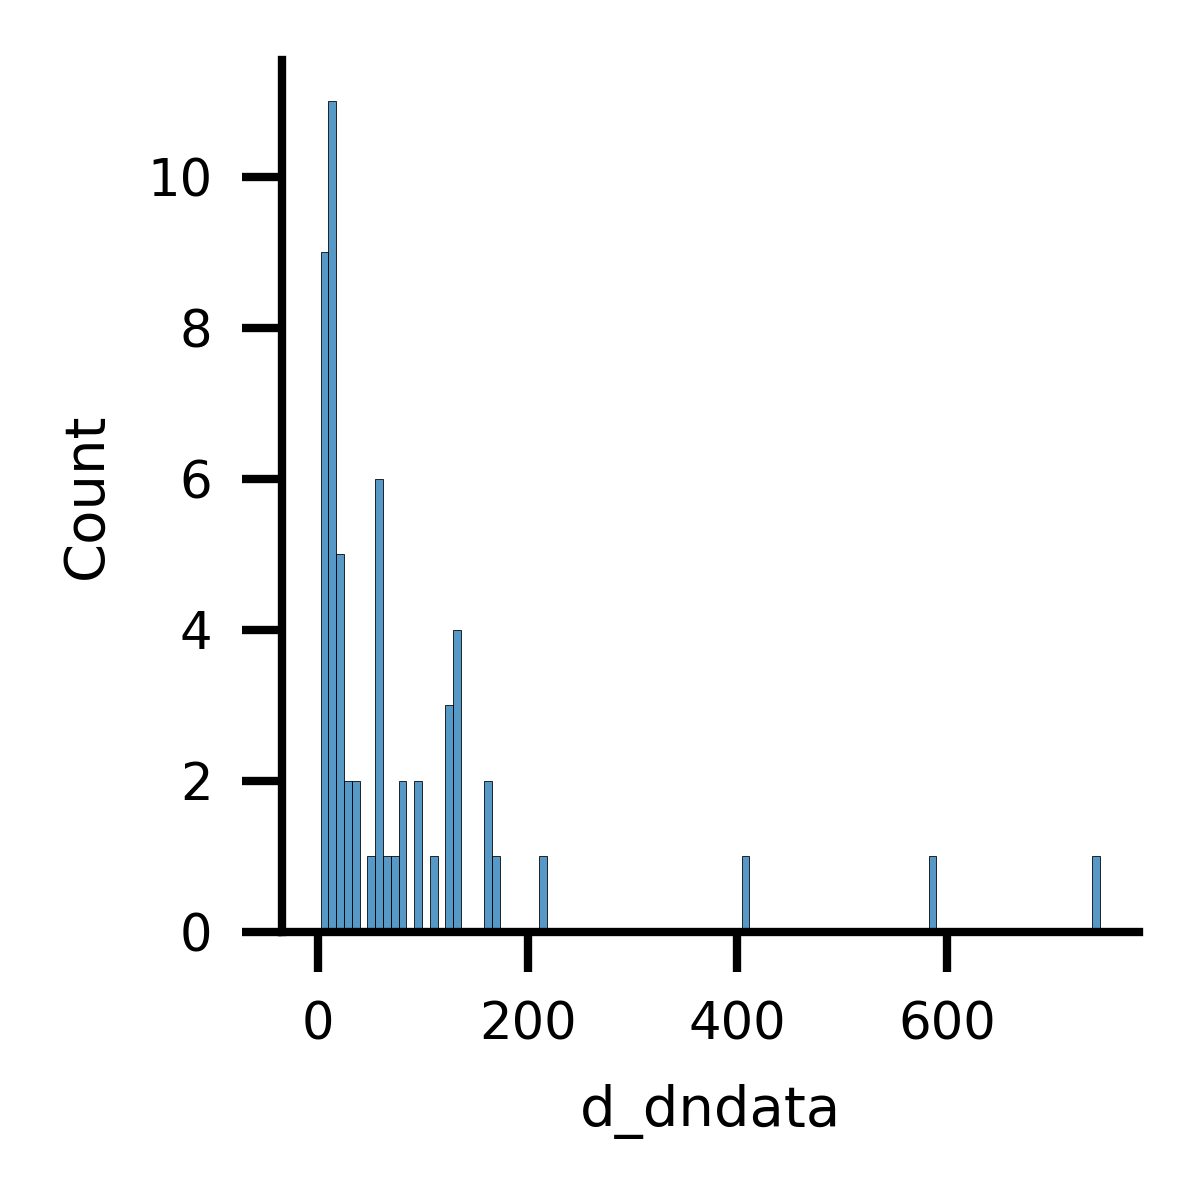

In [57]:
sns.displot(
    data=res2["d_dndata"],
    bins=100,
    height=2,
)

In [79]:
len(res)

1030

In [ ]:
res.loc[
    ["ASHGTJPOSUFTGB" in x for x in res["inchikey"]],
    ["p_median", "ri", "active_phase", "inchikey", "first_threshold"],
]

,p_median,ri,active_phase,inchikey,first_threshold
#,,,,,
ri23_011315_0006,2.28286,2.086,DB-FFAP,ASHGTJPOSUFTGB-UHFFFAOYSA-N,58.8


In [ ]:
res.loc[
    ["ASHGTJPOSUFTGB" in x for x in res["inchikey"]], MODEL_NAMES
].T

#,ri23_011315_0006
cnn-42,2.28286
cnn-43,2.26110
cnn-44,2.30040
cnn-45,2.40112
cnn-46,2.33870
fcd-42,2.19550
fcd-43,2.25872
fcd-44,2.22872
fcd-45,2.20091
fcd-46,2.27313


In [ ]:
res.loc[
    ["ASHGTJPOSUFTGB" in x for x in res["inchikey"]], MODEL_NAMES
].T.describe()

#,ri23_011315_0006
count,25.000000
mean,2.265643
std,0.132622
min,2.008480
25%,2.200910
50%,2.282860
75%,2.338700
max,2.469850


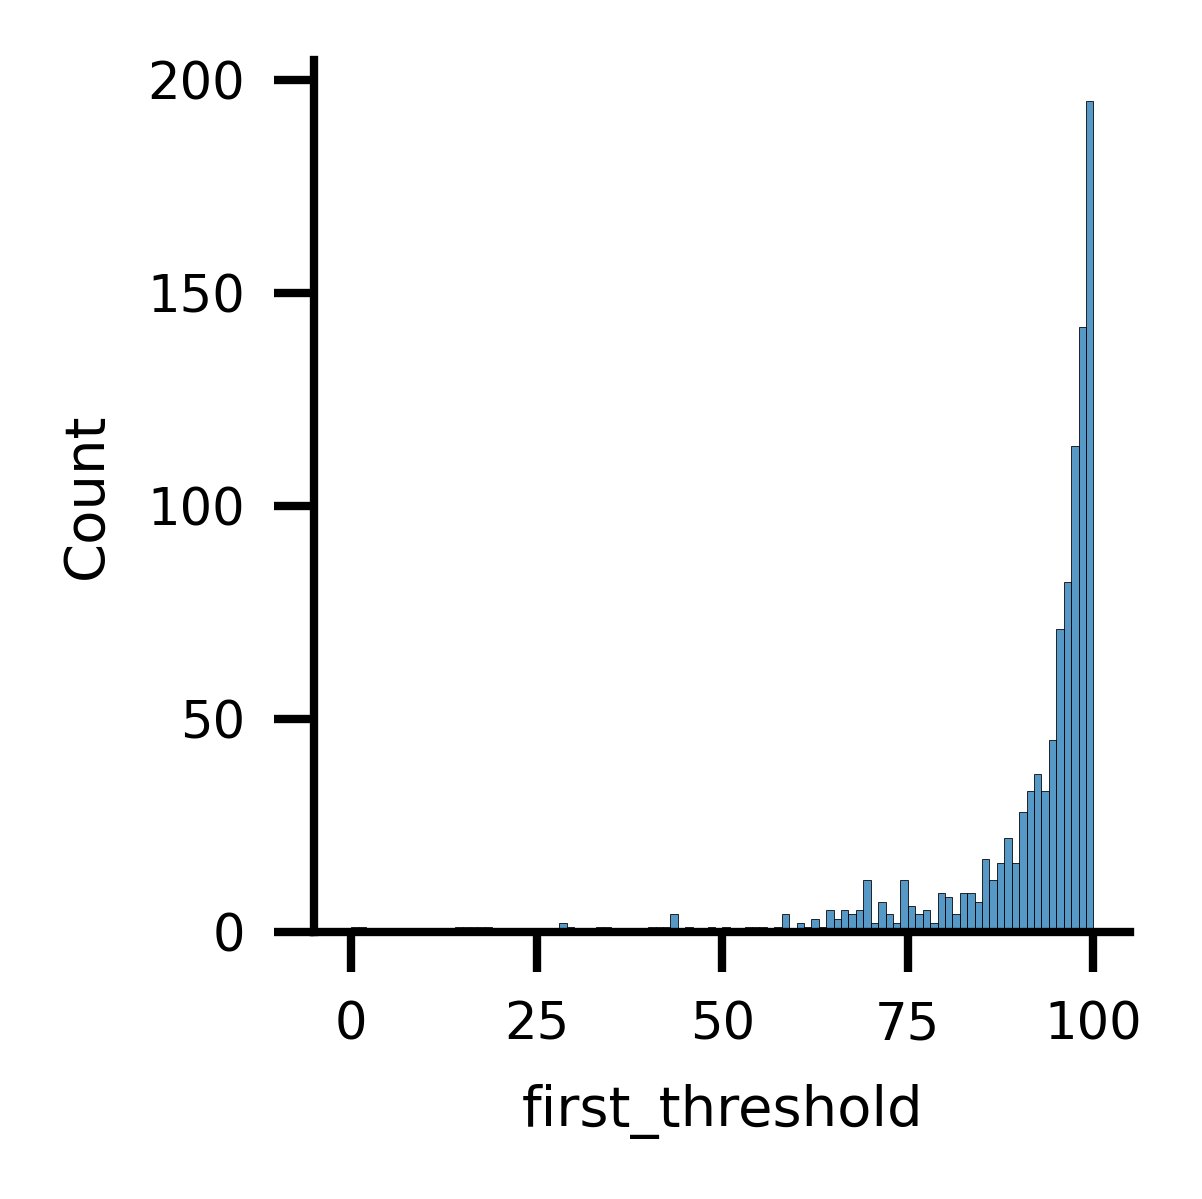

In [70]:
sns.displot(res["first_threshold"], bins=np.linspace(0, 100, 101), height=2)

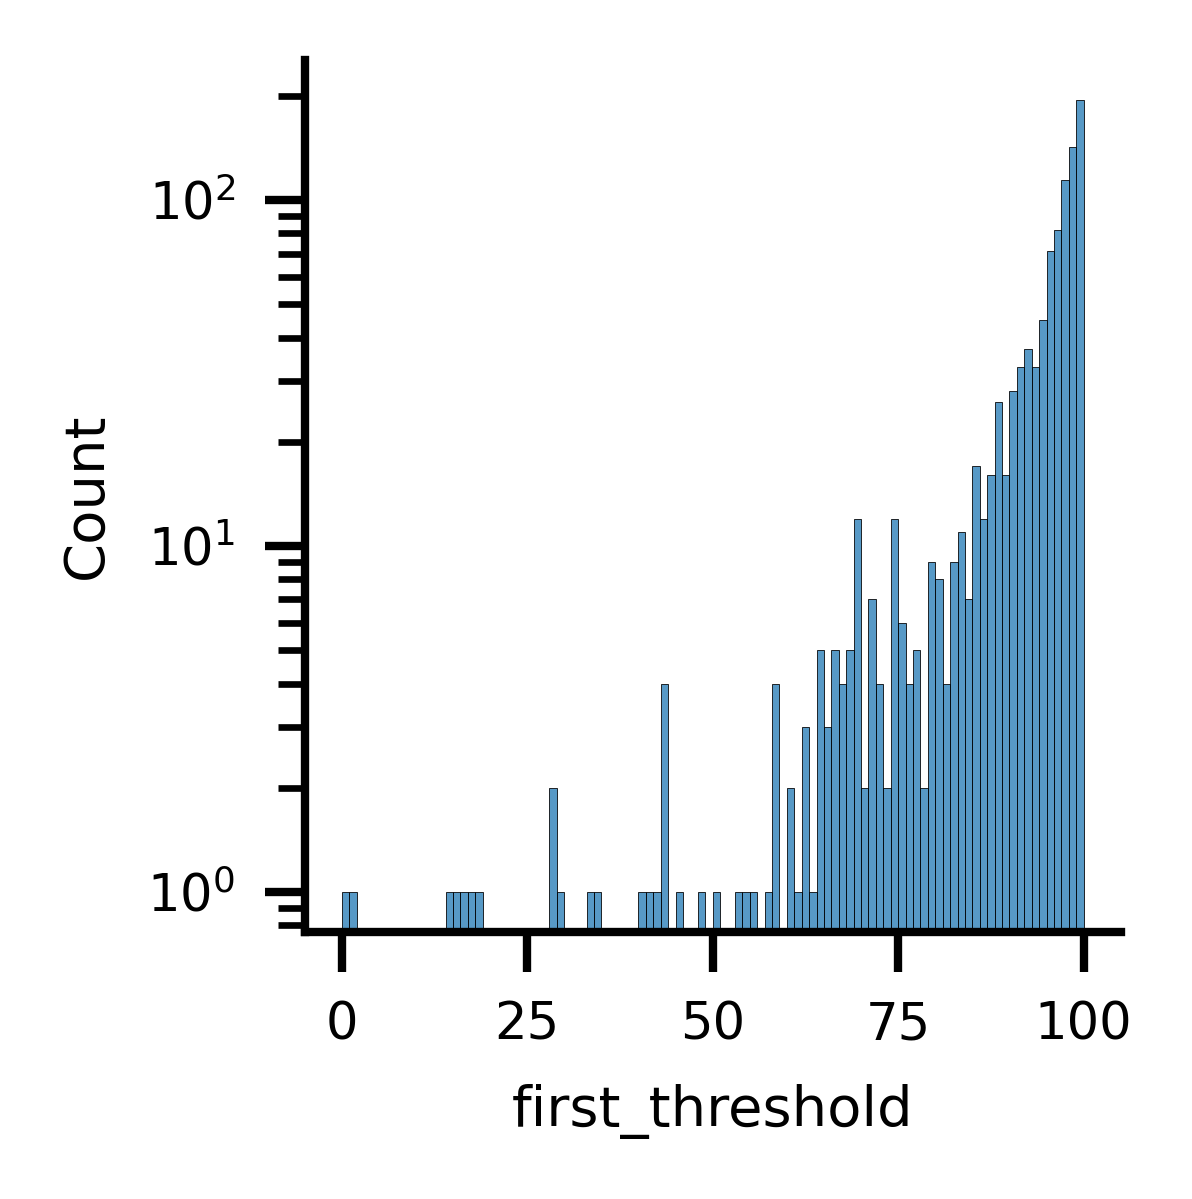

In [76]:
fg = sns.displot(res["first_threshold"], bins=np.linspace(0, 100, 101), height=2)
fg.set(yscale="log")

In [ ]:
polar_df.loc[polar_df["active_phase"] == "TC-FFAP", "source"].unique()

array(['Kurose, K.; Yatagai, M., Components of the essential oils of Azadirachta indica A. Juss, Azadirachta siamensis Velton, and Azadirachta excelsa (Jack) Jacobs and their comparison, J. Wood Sci., 51, 2005, 185-188.',
       'Kurose, K.; Okamura, D.; Yatagai, M., Composition of the essential oils from the leaves of nine Pinus species and the cones of three of Pinus species, Flavour Fragr. J., 22, 2007, 10-20.'],
      dtype=object)

In [ ]:
uc_df.loc[uc_df["active_phase"] == "TC-FFAP", "first_threshold"].describe()

count    211.000000
mean      87.418009
std       18.528744
min        1.700000
25%       85.900000
50%       94.600000
75%       98.300000
max      100.000000
Name: first_threshold, dtype: float64

In [ ]:
res.loc[
    ["QRUDEWIWKLJBPS" in x for x in res["inchikey"]], MODEL_NAMES
].T

#,ri23_055389_0002
cnn-42,2.31542
cnn-43,2.29127
cnn-44,2.26191
cnn-45,2.31644
cnn-46,2.35650
fcd-42,2.29515
fcd-43,2.40681
fcd-44,2.02585
fcd-45,2.34119
fcd-46,2.15676


In [ ]:
res.loc[
    ["QRUDEWIWKLJBPS" in x for x in res["inchikey"]], MODEL_NAMES
].T.describe()

#,ri23_055389_0002
count,25.000000
mean,2.247455
std,0.113861
min,2.025850
25%,2.147360
50%,2.291270
75%,2.342900
max,2.406810


In [ ]:
from nist_polar_filtering.preprocessing import load_nist_2023_dataset


ri_df, input_molecules = load_nist_2023_dataset(
    BASE_DIR / "data/input/nist_ri_2023_0.0.1.tsv"
)
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator


In [ ]:
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(radius=3, fpSize=4096)


In [ ]:
morgan_fingerprints = np.array(
    thread_map(
        morgan_generator.GetCountFingerprintAsNumPy,
        input_molecules,
        chunksize=500,
        max_workers=8,
    )
)

In [ ]:
polar_molecules = np.array(list(map(Chem.MolFromInchi, polar_df["inchi"])))
polar_fingerprints = np.array(
    thread_map(
        morgan_generator.GetCountFingerprintAsNumPy,
        polar_molecules,
        chunksize=500,
        max_workers=8,
    )
)
polar_inchikeys = polar_df["inchikey"]

In [ ]:
input_inchikeys = ri_df["inchikey"]

In [ ]:
ri_df.loc[ri_df["inchikey"] == "QRUDEWIWKLJBPS-UHFFFAOYSA-N"]

In [ ]:
morgan_fingerprints[input_inchikeys == "QRUDEWIWKLJBPS-UHFFFAOYSA-N"][0]

array([0, 0, 0, ..., 0, 1, 0], shape=(4096,), dtype=uint32)

In [176]:
def tanimoto_similarity(query_vector, vectors, eps=1e-12):
    """
    Compute Tanimoto similarity between one vector and multiple vectors.

    Parameters
    ----------
    query_vector : array-like, shape (d,)
        Reference vector.
    vectors : array-like, shape (n, d)
        Matrix of vectors to compare against.
    eps : float
        Small value to avoid division by zero.

    Returns
    -------
    similarities : np.ndarray, shape (n,)
        Tanimoto similarity scores.
    """
    q = np.asarray(query_vector, dtype=float)
    X = np.asarray(vectors, dtype=float)

    # Dot products
    dot = X @ q

    # Squared norms
    q_norm_sq = np.dot(q, q)
    X_norm_sq = np.sum(X * X, axis=1)

    # Tanimoto similarity
    similarities = dot / (q_norm_sq + X_norm_sq - dot + eps)

    return similarities

In [ ]:
res = tanimoto_similarity(
    morgan_fingerprints[input_inchikeys == "QRUDEWIWKLJBPS-UHFFFAOYSA-N"][0],
    morgan_fingerprints[input_inchikeys != "QRUDEWIWKLJBPS-UHFFFAOYSA-N"],
)
pd.Series(res).describe()

count    477412.000000
mean          0.105334
std           0.126464
min           0.000000
25%           0.000000
50%           0.048698
75%           0.193103
max           0.628205
dtype: float64

In [ ]:
res = tanimoto_similarity(
    polar_fingerprints[polar_inchikeys == "ASHGTJPOSUFTGB-UHFFFAOYSA-N"][0],
    polar_fingerprints[polar_inchikeys != "ASHGTJPOSUFTGB-UHFFFAOYSA-N"],
)
pd.Series(res).describe()

count    89468.000000
mean         0.116210
std          0.131622
min          0.000000
25%          0.026667
50%          0.050847
75%          0.158537
max          0.696429
dtype: float64

In [ ]:
res = tanimoto_similarity(
    polar_fingerprints[polar_inchikeys == "QRUDEWIWKLJBPS-UHFFFAOYSA-N"][0],
    polar_fingerprints[polar_inchikeys != "QRUDEWIWKLJBPS-UHFFFAOYSA-N"],
)
pd.Series(res).describe()

count    89468.000000
mean         0.082431
std          0.127139
min          0.000000
25%          0.000000
50%          0.011173
75%          0.110092
max          0.600000
dtype: float64